In [2]:
import pandas as pd
import yfinance as yf
from datetime import datetime
import time
from pathlib import Path
import seaborn as sns
import requests
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from scipy.special import softmax
import os
import torch.nn.functional as F
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import TimeSeriesSplit

In [3]:
tickers = [
    "BZ=F",     # Brent oil
    "CL=F",     # WTI oil
    "^GSPC",    # S&P 500
    "^VIX",     # VIX
    "NOK=X",    # USD/NOK
    "^OSEBX",   # Oslo Stock Exchange index
    "EQNR.OL",  # Equinor
    "^TNX"      # US 10Y yield
]
data = yf.download(
    tickers,
    start="2015-01-01",
    end="2025-12-31",
    interval="1d",
    auto_adjust=True
)


[*********************100%***********************]  8 of 8 completed


In [4]:
prices = data["Close"]
prices = prices.ffill()

In [5]:
returns = np.log(prices / prices.shift(1))
returns = returns.dropna()

In [6]:
returns = returns.rename(
    columns={
        "BZ=F": "Brent_oil",
        "CL=F": "WTI_oil",
        "^GSPC": "SP500",
        "^VIX": "VIX",
        "NOK=X": "USDNOK",
        "^OSEBX": "OSEBX",
        "EQNR.OL": "Equinor",
        "^TNX": "US10Y"
    }
)

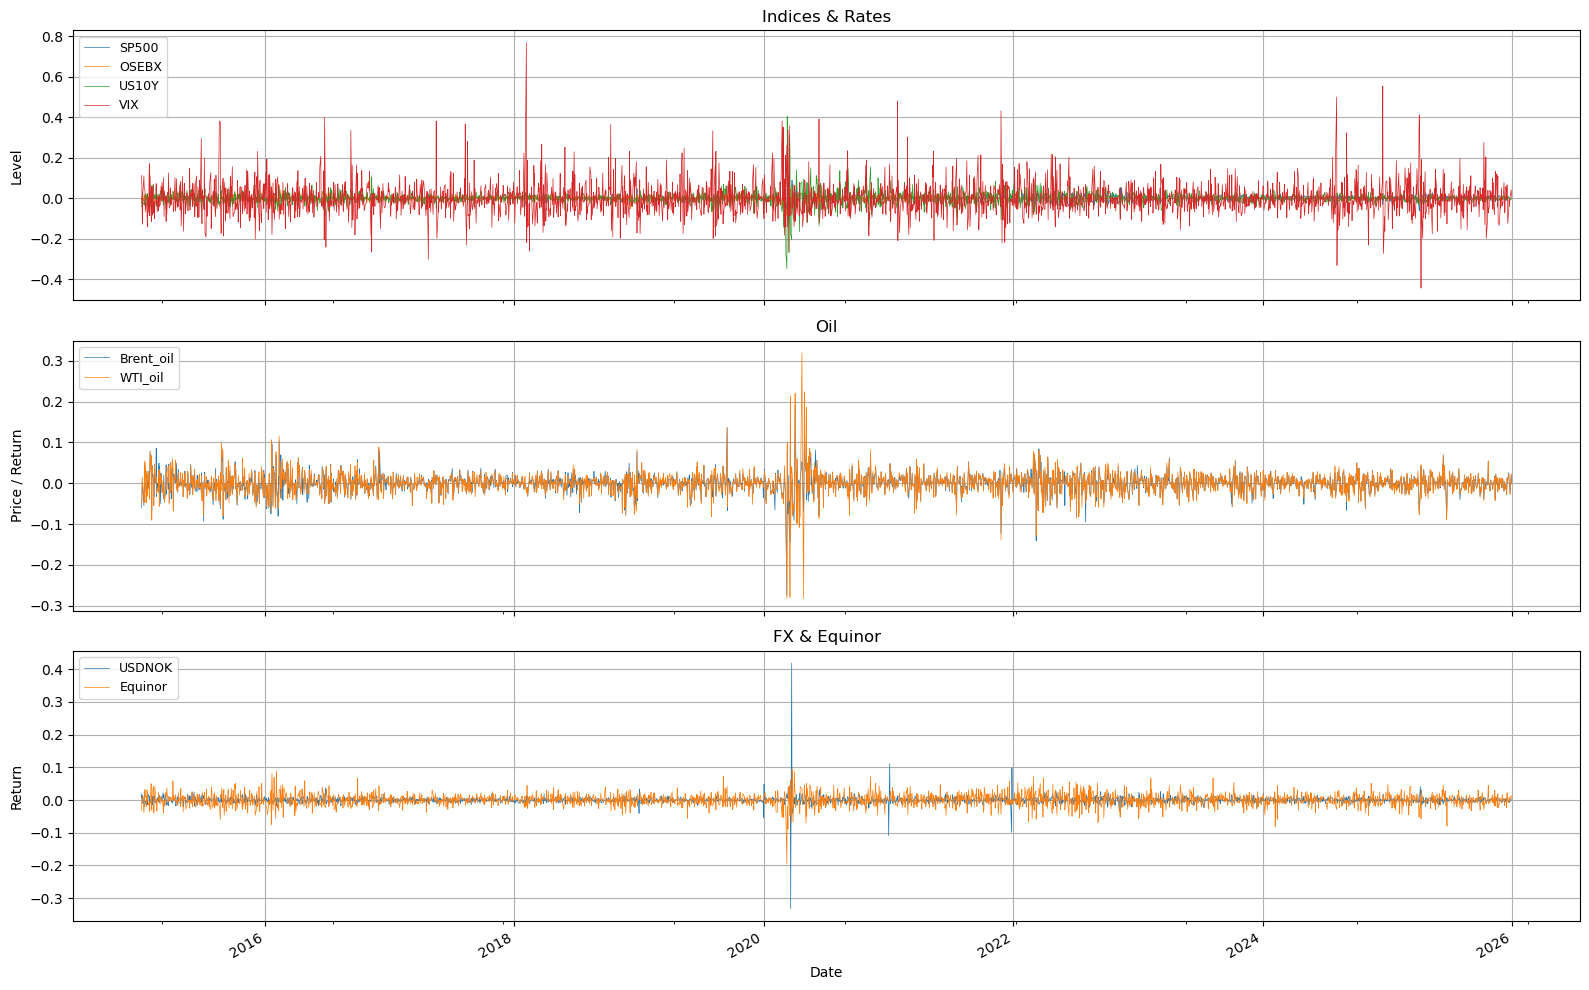

In [7]:
import matplotlib.pyplot as plt

plot_df = returns.copy()

fig, axes = plt.subplots(
    nrows=3, ncols=1,
    figsize=(16, 10),
    sharex=True
)

# 1) Macro / indices
plot_df[["SP500", "OSEBX", "US10Y", "VIX"]].plot(
    ax=axes[0], linewidth=0.5
)
axes[0].set_title("Indices & Rates")
axes[0].set_ylabel("Level")
axes[0].grid(True)

# 2) Commodities
plot_df[["Brent_oil", "WTI_oil"]].plot(
    ax=axes[1], linewidth=0.5
)
axes[1].set_title("Oil")
axes[1].set_ylabel("Price / Return")
axes[1].grid(True)

# 3) FX & stock
plot_df[["USDNOK", "Equinor"]].plot(
    ax=axes[2], linewidth=0.5
)
axes[2].set_title("FX & Equinor")
axes[2].set_ylabel("Return")
axes[2].grid(True)

for ax in axes:
    ax.legend(loc="upper left", fontsize=9)

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()


In [9]:
returns.to_csv("Macro_variables.csv")

In [8]:
corr = returns.corr()
print(corr['Equinor'].sort_values(ascending=False))

Ticker
Equinor      1.000000
OSEBX        0.603568
Brent_oil    0.438742
WTI_oil      0.416666
US10Y        0.226037
SP500        0.204371
USDNOK      -0.068143
VIX         -0.164244
Name: Equinor, dtype: float64


API_KEY = "69b0708f4cd2a5.94606251"
BASE_URL = "https://eodhd.com/api/news"

analyzer = SentimentIntensityAnalyzer()
all_articles = []

for year in range(2015, 2026):
    print(f"Downloading news for {year}")

    params = {
        "t": "oil",
        "from": f"{year}-01-01",
        "to": f"{year}-12-31",
        "limit": 200,
        "offset": 0,
        "api_token": API_KEY,
        "fmt": "json"
    }

    while True:
        response = requests.get(BASE_URL, params=params, timeout=30)

        if response.status_code != 200:
            print(f"HTTP error {response.status_code} for year {year}, offset {params['offset']}")
            print(response.text[:500])
            break

        try:
            data = response.json()
        except ValueError:
            print(f"Non-JSON response for year {year}, offset {params['offset']}")
            print(response.text[:500])
            break

        if not data:
            print(f"No more data for {year}")
            break

        if isinstance(data, dict) and data.get("error"):
            print(f"API error for year {year}: {data}")
            break

        for article in data:
            headline = article.get("title", "")
            date = article.get("date", "")
            link = article.get("link", "")

            sentiment = analyzer.polarity_scores(headline)["compound"]

            all_articles.append({
                "date": date,
                "headline": headline,
                "sentiment": sentiment,
                "link": link
            })

        print(f"  got {len(data)} rows at offset {params['offset']}")

        if len(data) < params["limit"]:
            break

        params["offset"] += params["limit"]
        time.sleep(1.2)

df = pd.DataFrame(all_articles)

if not df.empty:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df = df.sort_values("date")
    df.to_csv("oil_news_sentiment_2015_2025.csv", index=False)
    print("Finished")
    print(df.head())
else:
    print("No data collected.")

In [13]:
sentiment = pd.read_csv("oil_news_sentiment_2015_2025.csv")


In [14]:
model_path = r"C:\\Users\\im_co\\Desktop\\exam"
# Verify all files exist
required_files = ['pytorch_model.bin', 'config.json', 'vocab.txt']
missing = [f for f in required_files if not os.path.exists(os.path.join(model_path, f))]
if missing:
    print(f"❌ Missing files: {missing}")
    print("Please download these files to the folder.")
else:
    print("✅ All files present! Loading model...")
    
    # Load model
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model = AutoModelForSequenceClassification.from_pretrained(model_path)
    
    # Test it
    def get_sentiment(text):
        inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=512)
        with torch.no_grad():
            outputs = model(**inputs)
            probs = F.softmax(outputs.logits, dim=-1)
            return probs[0][0].item() - probs[0][1].item()  # positive - negative
    
    # Test
    test_text = "Oil prices surge on OPEC production cuts"
    score = get_sentiment(test_text)
    print(f"\nTest headline: '{test_text}'")
    print(f"Sentiment score: {score:.4f}")

✅ All files present! Loading model...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: C:\\Users\\im_co\\Desktop\\exam
Key                          | Status     |  | 
-----------------------------+------------+--+-
bert.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Test headline: 'Oil prices surge on OPEC production cuts'
Sentiment score: -0.4665


In [15]:
 def get_finbert_score(text):
        if pd.isna(text) or str(text).strip() == "":
            return 0.0
        inputs = tokenizer(str(text), return_tensors="pt", truncation=True, padding=True, max_length=512)
        with torch.no_grad():
            outputs = model(**inputs)
            
            probs = F.softmax(outputs.logits[0], dim=0).numpy()  
        return probs[2] - probs[0]

In [16]:
tqdm.pandas()
sentiment['finbert_sentiment'] = sentiment['headline'].progress_apply(get_finbert_score)

100%|██████████| 1947/1947 [02:00<00:00, 16.22it/s]


In [17]:
df_senti = sentiment.copy()


In [18]:
df_senti = df_senti.rename(columns={'sentiment': 'vader_sentiment'})

In [19]:
df_senti['date'] = pd.to_datetime(df_senti['date'])
df_senti['date'] = df_senti['date'].dt.date
df_daily_sentiment = df_senti.groupby('date')[['vader_sentiment', 'finbert_sentiment']].mean().reset_index()

print("Daily sentiment DataFrame:")
display(df_daily_sentiment.head())

Daily sentiment DataFrame:


,date,vader_sentiment,finbert_sentiment
0,2015-07-06,0.281550,0.367143
1,2015-07-07,0.099667,0.135614
2,2015-07-08,0.180600,0.889745
3,2015-07-09,0.000000,0.672011
4,2015-07-10,0.273200,0.894756


In [21]:
data_reset = returns.reset_index()
# Flatten the MultiIndex columns to a single level, using the first level names
data_reset.columns = data_reset.columns.get_level_values(0)
data_reset.rename(columns={'Date': 'date'}, inplace=True)

data_reset['date'] = pd.to_datetime(data_reset['date'])
df_daily_sentiment['date'] = pd.to_datetime(df_daily_sentiment['date'])

merged_df = pd.merge(data_reset, df_daily_sentiment, on='date', how='left')

display(merged_df.head())

,date,Brent_oil,WTI_oil,Equinor,USDNOK,SP500,OSEBX,US10Y,VIX,vader_sentiment,finbert_sentiment
0,2015-01-05,-0.060458,-0.051603,-0.032022,0.019638,-0.018447,-0.024302,-0.040371,0.113088,NaN,NaN
1,2015-01-06,-0.038581,-0.043081,0.010265,0.003959,-0.008933,0.007979,-0.037986,0.058496,NaN,NaN
2,2015-01-07,0.000978,0.014910,0.009383,0.014290,0.011563,0.005913,-0.004595,-0.089597,NaN,NaN
3,2015-01-08,-0.003722,0.002874,0.008524,-0.005980,0.017730,0.011635,0.031237,-0.126822,NaN,NaN
4,2015-01-09,-0.016820,-0.008852,0.009216,-0.010132,-0.008439,0.000638,-0.022574,0.031252,NaN,NaN


In [22]:
merged_df[['vader_sentiment', 'finbert_sentiment']] = merged_df[['vader_sentiment', 'finbert_sentiment']].replace(0, pd.NA)
merged_df[['vader_sentiment', 'finbert_sentiment']] = merged_df[['vader_sentiment', 'finbert_sentiment']].ffill()

C:\Users\im_co\AppData\Local\Temp\ipykernel_1028\2241180946.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  merged_df[['vader_sentiment', 'finbert_sentiment']] = merged_df[['vader_sentiment', 'finbert_sentiment']].ffill()


In [23]:
merged_df = merged_df.dropna()

In [24]:
merged_df = merged_df.set_index('date')

In [25]:
models = {

    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LinearRegression()),  ]),
    
    "RandomForest": RandomForestRegressor(
        n_estimators=400,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),
    
    "XGBoost": XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=42,
        n_jobs=-1
    ),
    
    "LightGBM": LGBMRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=5,
        num_leaves=31,
        random_state=42
    ),
    
    "MLP": Pipeline([
    ("scaler", StandardScaler()), 
    ("mlp", MLPRegressor(
        # Smaller layers to prevent overfitting on 7 features
        hidden_layer_sizes=(32, 16), 
        activation="relu",
        # Alpha is L2 regularization - higher values (0.1+) 
        # force the model to be 'simpler' and less noisy
        alpha=0.1, 
        # Learning rate initialization
        learning_rate_init=0.001,
        # Early stopping is critical: it stops training 
        # when the validation score stops improving
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        max_iter=2000, 
        random_state=42
        ))
    ])
}

In [26]:
def make_train_test_with_drops(
    df,
    target_col,
    drop_cols=None,
    train_start='2015-01-01',
    train_end='2023-12-31',
    test_start='2024-01-01'
):
    if target_col not in df.columns:
        raise ValueError(f"Target column '{target_col}' not found in DataFrame.")

    if not isinstance(df.index, pd.DatetimeIndex):
        raise TypeError("DataFrame index must be a pandas DatetimeIndex.")

    df = df.sort_index()

    # Create train and test splits
    train_df = df.loc[train_start:train_end].copy()
    test_df = df.loc[test_start:].copy()

    if train_df.empty:
        raise ValueError("Training set is empty. Check train_start and train_end.")
    if test_df.empty:
        raise ValueError("Test set is empty. Check test_start.")

    if drop_cols is None:
        drop_cols = []

    drop_cols = [col for col in drop_cols if col != target_col]

    cols_to_drop = [col for col in drop_cols if col in df.columns]
    train_df = train_df.drop(columns=cols_to_drop)
    test_df = test_df.drop(columns=cols_to_drop)

    X_train = train_df.drop(columns=[target_col])
    y_train = train_df[target_col]

    X_test = test_df.drop(columns=[target_col])
    y_test = test_df[target_col]

    return X_train, X_test, y_train, y_test

In [27]:
def run_models(X_train, X_test, y_train, y_test, models):
    results = []
    test_predictions = {}
    
    print("Fitting & evaluating models...")
    for name, model in models.items():
        model.fit(X_train, y_train)
        
        y_pred_test = model.predict(X_test)
        test_predictions[name] = y_pred_test
        
        mse = mean_squared_error(y_test, y_pred_test)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_test, y_pred_test)
        r2 = r2_score(y_test, y_pred_test)
        
        # Hit ratio: correct sign of move (exclude exact zeros if you want)
        actual_sign = np.sign(y_test.values)
        pred_sign = np.sign(y_pred_test)
        hit_ratio = (actual_sign == pred_sign).mean()
        
        results.append({
            'Model': name,
            'Test_MAE': mae,
            'Test_RMSE': rmse,
            'Test_MSE': mse,
            'Test_R2': r2,
            'Hit_Ratio': hit_ratio,
            'Features': X_train.shape[1]
        })
        print(
            f"{name}: R²={r2:.4f}, RMSE={rmse:.6f}, MAE={mae:.6f}, "
            f"HitRatio={hit_ratio:.4f}"
        )
    
    results_df = pd.DataFrame(results).round(6)
    # Sort primarily by R2, secondarily by Hit_Ratio
    results_df = results_df.sort_values(['Test_R2', 'Hit_Ratio'], ascending=False).reset_index(drop=True)
    return results_df, test_predictions

In [28]:
def plot_full_with_test_preds(
    results_df,
    test_predictions,
    y_train,
    y_test,
    title_prefix="",
    top_n=2,
    test_start_line_color="red"
):
       # Concatenate full actual series
    y_full = pd.concat([y_train, y_test])
    
    # Pick best models by Test_R2
    best_models = (
        results_df.sort_values('Test_R2', ascending=False)['Model']
        .head(top_n)
        .tolist()
    )

    plt.figure(figsize=(16, 6))

    # Plot full actual series
    plt.plot(
        y_full.index,
        y_full.values,
        label='Actual Equinor (train+test)',
        color='black',
        linewidth=2,
    )

    
    for name in best_models:
        if name not in test_predictions:
            continue
        plt.plot(
            y_test.index,
            test_predictions[name],
            label=f'{name} prediction (test)',
            alpha=0.8,
        )

    
    test_start_date = y_test.index[0]
    plt.axvline(
        x=test_start_date,
        color=test_start_line_color,
        linestyle='--',
        linewidth=2,
        label='Test start',
    )

    title = (
        f'{title_prefix} Equinor: Train+Test with Test Predictions'
        if title_prefix
        else 'Equinor: Train+Test with Test Predictions'
    )
    plt.title(title)
    plt.xlabel('Date')
    plt.ylabel('Equinor (returns or price)')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [29]:
X_oiltrain, X_oiltest, y_oiltrain, y_oiltest = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["OSEBX","vader_sentiment","USDNOK","SP500","US10Y","VIX","finbert_sentiment"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)

In [30]:
X_localtrain, X_localtest, y_localtrain, y_localtest = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["vader_sentiment","SP500","US10Y","VIX","finbert_sentiment","Brent_oil","WTI_oil"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)

In [31]:
X_macrotrain, X_macrotest, y_macrotrain, y_macrotest = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["OSEBX","vader_sentiment","USDNOK","finbert_sentiment","Brent_oil","WTI_oil"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)

In [32]:
X_fulltrain, X_fulltest, y_fulltrain, y_fulltest = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["vader_sentiment","finbert_sentiment"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)

In [33]:
results_fulldf, test_fullpredictions = run_models(
    X_fulltrain, X_fulltest, y_fulltrain, y_fulltest, models
)


Fitting & evaluating models...
LinearRegression: R²=0.1092, RMSE=0.015558, MAE=0.011320, HitRatio=0.5530
RandomForest: R²=0.1276, RMSE=0.015397, MAE=0.011293, HitRatio=0.5511
XGBoost: R²=0.1001, RMSE=0.015637, MAE=0.011388, HitRatio=0.5684
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000362 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1785
[LightGBM] [Info] Number of data points in the train set: 2213, number of used features: 7
[LightGBM] [Info] Start training from score 0.000552
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with p

In [34]:
results_oildf, test_oilpredictions = run_models(
    X_oiltrain, X_oiltest, y_oiltrain, y_oiltest, models
)

Fitting & evaluating models...
LinearRegression: R²=0.1256, RMSE=0.015414, MAE=0.011297, HitRatio=0.5626
RandomForest: R²=0.0706, RMSE=0.015892, MAE=0.011686, HitRatio=0.5434
XGBoost: R²=0.0713, RMSE=0.015885, MAE=0.011665, HitRatio=0.5511
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000076 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 510
[LightGBM] [Info] Number of data points in the train set: 2213, number of used features: 2
[LightGBM] [Info] Start training from score 0.000552
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with po

In [35]:
results_localdf, test_localpredictions = run_models(
    X_localtrain, X_localtest, y_localtrain, y_localtest, models
)

Fitting & evaluating models...
LinearRegression: R²=-0.0030, RMSE=0.016508, MAE=0.011802, HitRatio=0.4913
RandomForest: R²=-0.0174, RMSE=0.016627, MAE=0.011995, HitRatio=0.4740
XGBoost: R²=-0.0247, RMSE=0.016686, MAE=0.012042, HitRatio=0.4663
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000075 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 510
[LightGBM] [Info] Number of data points in the train set: 2213, number of used features: 2
[LightGBM] [Info] Start training from score 0.000552
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

In [36]:
results_macrodf, test_macropredictions = run_models(
    X_macrotrain, X_macrotest, y_macrotrain, y_macrotest, models
)

Fitting & evaluating models...
LinearRegression: R²=-0.0660, RMSE=0.017019, MAE=0.012107, HitRatio=0.4933
RandomForest: R²=-0.0454, RMSE=0.016854, MAE=0.012102, HitRatio=0.5067
XGBoost: R²=-0.1468, RMSE=0.017652, MAE=0.012364, HitRatio=0.5048
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000751 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 765
[LightGBM] [Info] Number of data points in the train set: 2213, number of used features: 3
[LightGBM] [Info] Start training from score 0.000552
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with

In [38]:
print("\nBest Models for Equinor (no sentiment features) with Full features:")
print(results_fulldf)
print("\nBest Models for Equinor (no sentiment features) with only macro features:")
print(results_macrodf)
print("\nBest Models for Equinor (no sentiment features): with only local features")
print(results_localdf)
print("\nBest Models for Equinor (no sentiment features):with only oil features")
print(results_oildf)


Best Models for Equinor (no sentiment features) with Full features:
              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.011293   0.015397  0.000237  0.127596   0.551060   
1  LinearRegression  0.011320   0.015558  0.000242  0.109204   0.552987   
2           XGBoost  0.011388   0.015637  0.000245  0.100083   0.568401   
3               MLP  0.011415   0.015639  0.000245  0.099853   0.560694   
4          LightGBM  0.011467   0.015642  0.000245  0.099599   0.562620   

   Features  
0         7  
1         7  
2         7  
3         7  
4         7  

Best Models for Equinor (no sentiment features) with only macro features:
              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.012102   0.016854  0.000284 -0.045396   0.506744   
1  LinearRegression  0.012107   0.017019  0.000290 -0.065969   0.493256   
2          LightGBM  0.012569   0.017337  0.000301 -0.106156   0.495183   
3           XGBoost  

C:\Users\im_co\AppData\Local\Temp\ipykernel_1028\2028179166.py:62: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()


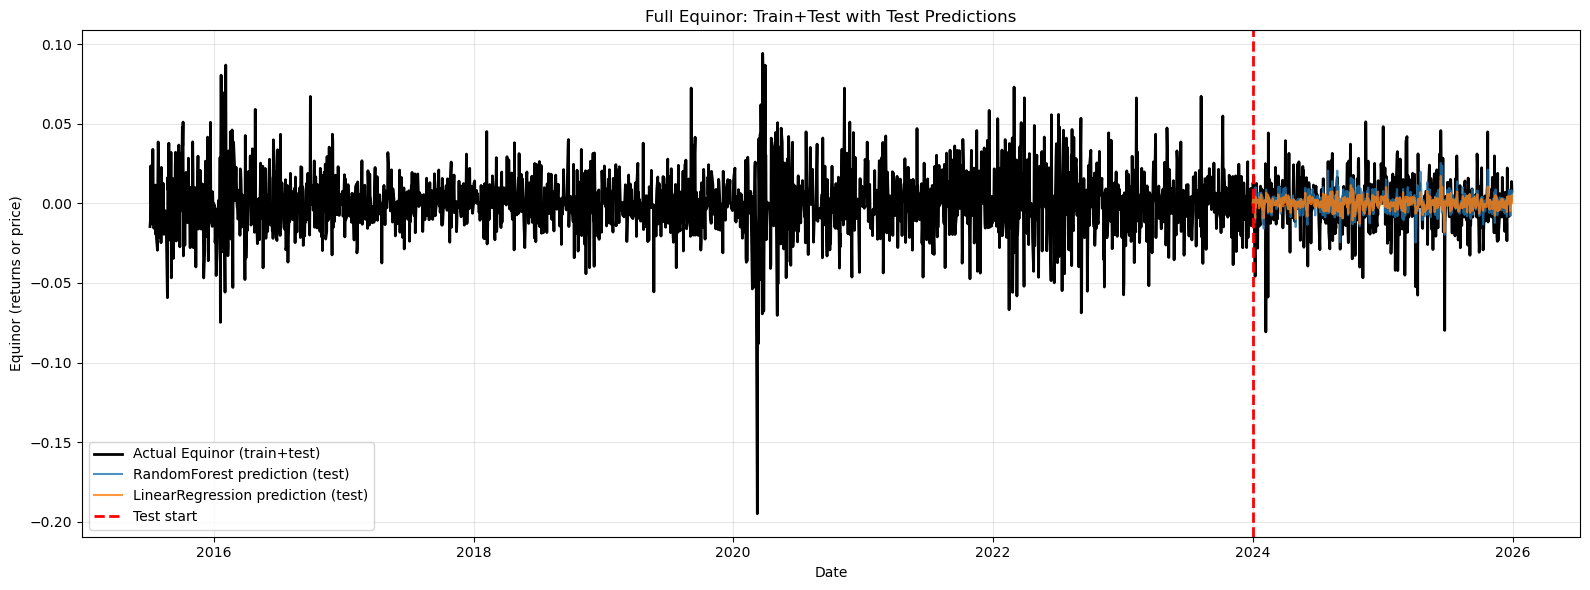

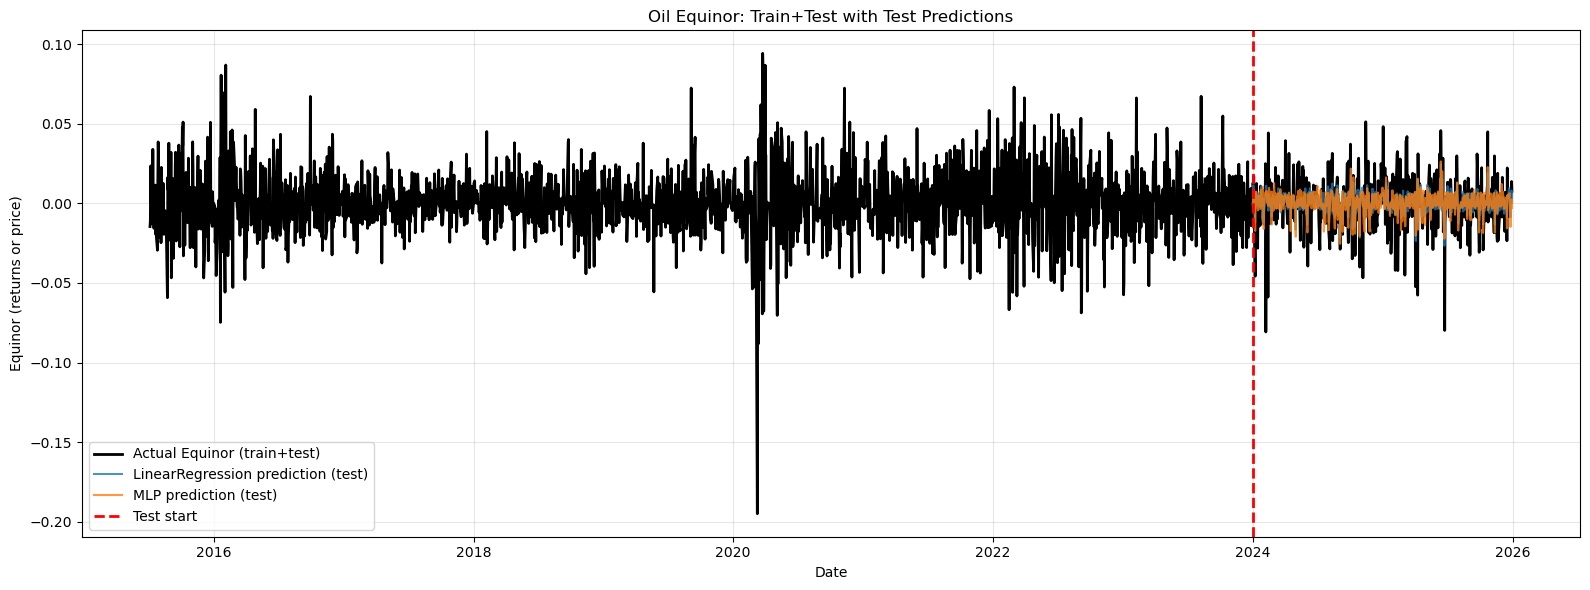

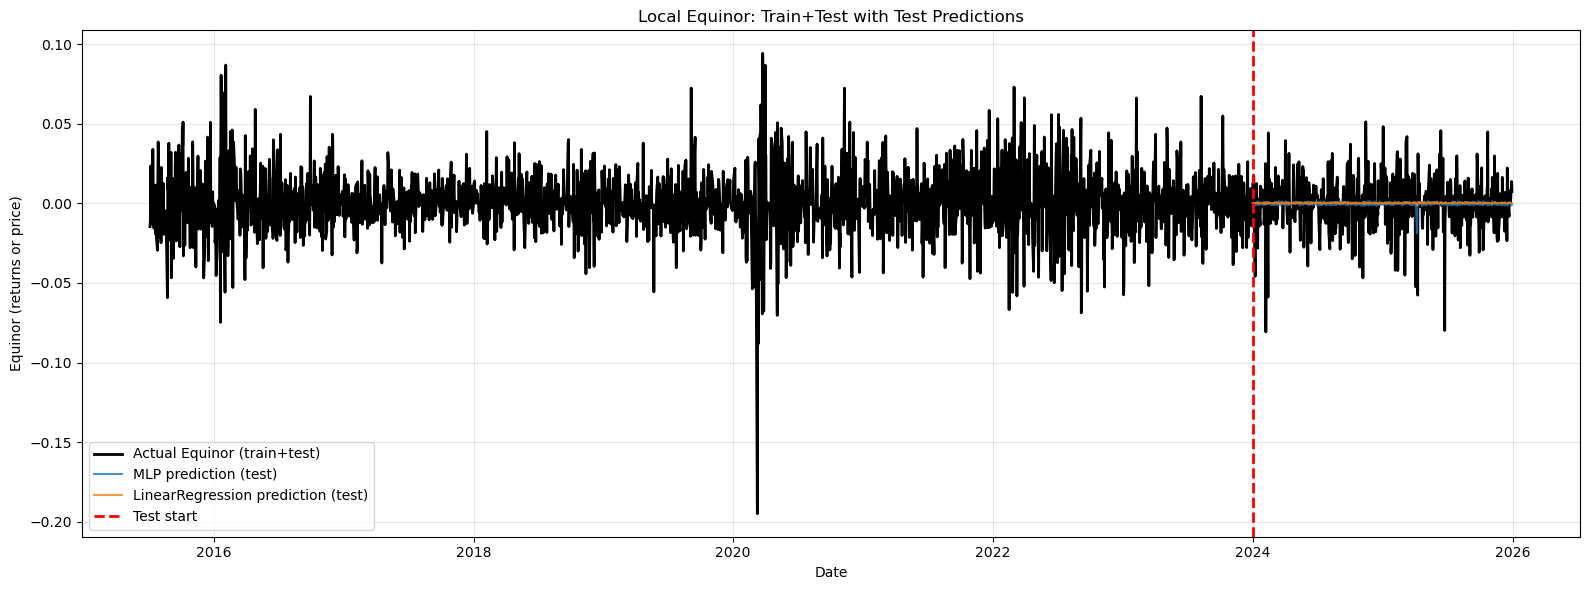

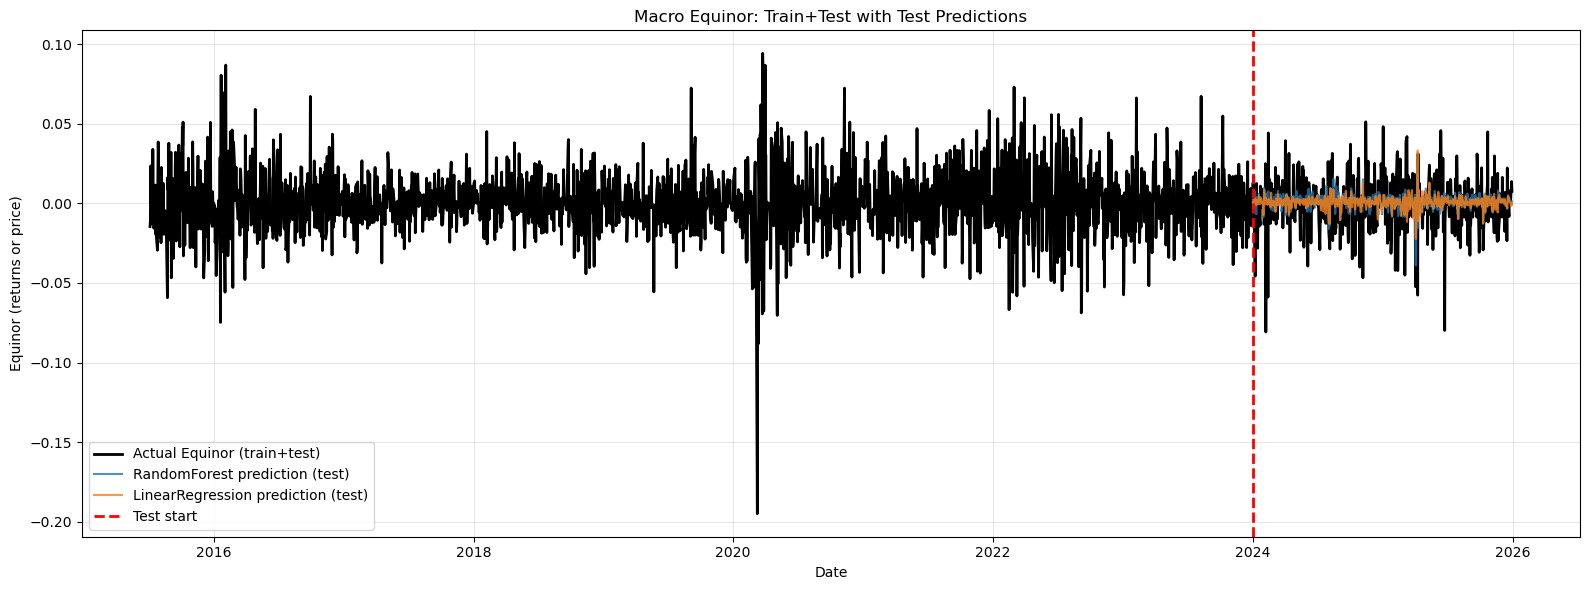

In [40]:
plot_full_with_test_preds(
    results_fulldf,
    test_fullpredictions,
    y_fulltrain,
    y_fulltest,
    title_prefix="Full",
    top_n=2
)

# Oil-only
plot_full_with_test_preds(
    results_oildf,
    test_oilpredictions,
    y_oiltrain,
    y_oiltest,
    title_prefix="Oil",
    top_n=2
)

# Local-only
plot_full_with_test_preds(
    results_localdf,
    test_localpredictions,
    y_localtrain,
    y_localtest,
    title_prefix="Local",
    top_n=2
)

# Macro-only
plot_full_with_test_preds(
    results_macrodf,
    test_macropredictions,
    y_macrotrain,
    y_macrotest,
    title_prefix="Macro",
    top_n=2
)

In [41]:
# With both the sentiment
X_oiltrain_fullsenti, X_oiltest_fullsenti, y_oiltrain_fullsenti, y_oiltest_fullsenti = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["OSEBX","USDNOK","SP500","US10Y","VIX"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)
X_localtrain_fullsenti, X_localtest_fullsenti, y_localtrain_fullsenti, y_localtest_fullsenti = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["SP500","US10Y","VIX","Brent_oil","WTI_oil"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)
X_macrotrain_fullsenti, X_macrotest_fullsenti, y_macrotrain_fullsenti, y_macrotest_fullsenti = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["OSEBX","USDNOK","Brent_oil","WTI_oil"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)
X_fulltrain_fullsenti, X_fulltest_fullsenti, y_fulltrain_fullsenti, y_fulltest_fullsenti = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=[],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)

In [42]:
# with only Finbert
X_oiltrain_finbert, X_oiltest_finbert, y_oiltrain_finbert, y_oiltest_finbert = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["OSEBX","vader_sentiment","USDNOK","SP500","US10Y","VIX"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)
X_localtrain_finbert, X_localtest_finbert, y_localtrain_finbert, y_localtest_finbert = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["vader_sentiment","SP500","US10Y","VIX","Brent_oil","WTI_oil"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)
X_macrotrain_finbert, X_macrotest_finbert, y_macrotrain_finbert, y_macrotest_finbert = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["OSEBX","vader_sentiment","USDNOK","Brent_oil","WTI_oil"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)
X_fulltrain_finbert, X_fulltest_finbert, y_fulltrain_finbert, y_fulltest_finbert = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["vader_sentiment"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)

In [43]:
#with only Vader
X_oiltrain_vader, X_oiltest_vader, y_oiltrain_vader, y_oiltest_vader = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["OSEBX","vader_sentiment","USDNOK","SP500","US10Y","VIX","finbert_sentiment"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)
X_localtrain_vader, X_localtest_vader, y_localtrain_vader, y_localtest_vader = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["vader_sentiment","SP500","US10Y","VIX","finbert_sentiment","Brent_oil","WTI_oil"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)
X_macrotrain_vader, X_macrotest_vader, y_macrotrain_vader, y_macrotest_vader = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["OSEBX","vader_sentiment","USDNOK","finbert_sentiment","Brent_oil","WTI_oil"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)
X_fulltrain_vader, X_fulltest_vader, y_fulltrain_vader, y_fulltest_vader = make_train_test_with_drops(
    df=merged_df,
    target_col="Equinor",
    drop_cols=["vader_sentiment","finbert_sentiment"],
    train_start="2015-01-01",
    train_end="2023-12-31",
    test_start="2024-01-01"
)

In [44]:
results_fulldf_fullsenti, test_fullpredictions_fullsenti = run_models(
    X_fulltrain_fullsenti, X_fulltest_fullsenti, y_fulltrain_fullsenti, y_fulltest_fullsenti, models
)
results_oildf_fullsenti, test_oilpredictions_fullsenti = run_models(
    X_oiltrain_fullsenti, X_oiltest_fullsenti, y_oiltrain_fullsenti, y_oiltest_fullsenti, models
)
results_localdf_fullsenti, test_localpredictions_fullsenti = run_models(
    X_localtrain_fullsenti, X_localtest_fullsenti, y_localtrain_fullsenti, y_localtest_fullsenti, models
)
results_macrodf_fullsenti, test_macropredictions_fullsenti = run_models(
    X_macrotrain_fullsenti, X_macrotest_fullsenti, y_macrotrain_fullsenti, y_macrotest_fullsenti, models
)

Fitting & evaluating models...
LinearRegression: R²=0.1084, RMSE=0.015565, MAE=0.011331, HitRatio=0.5453
RandomForest: R²=0.1226, RMSE=0.015441, MAE=0.011309, HitRatio=0.5472
XGBoost: R²=0.1148, RMSE=0.015509, MAE=0.011351, HitRatio=0.5588
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000117 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2251
[LightGBM] [Info] Number of data points in the train set: 2213, number of used features: 9
[LightGBM] [Info] Start training from score 0.000552
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with p

In [45]:
results_fulldf_finbert, test_fullpredictions_finbert = run_models(
    X_fulltrain_finbert, X_fulltest_finbert, y_fulltrain_finbert, y_fulltest_finbert, models
)
results_oildf_finbert, test_oilpredictions_finbert = run_models(
    X_oiltrain_finbert, X_oiltest_finbert, y_oiltrain_finbert, y_oiltest_finbert, models
)
results_localdf_finbert, test_localpredictions_finbert = run_models(
    X_localtrain_finbert, X_localtest_finbert, y_localtrain_finbert, y_localtest_finbert, models
)
results_macrodf_finbert, test_macropredictions_finbert = run_models(
    X_macrotrain_finbert, X_macrotest_finbert, y_macrotrain_finbert, y_macrotest_finbert, models
)

Fitting & evaluating models...
LinearRegression: R²=0.1093, RMSE=0.015557, MAE=0.011319, HitRatio=0.5530
RandomForest: R²=0.1287, RMSE=0.015387, MAE=0.011291, HitRatio=0.5491
XGBoost: R²=0.1088, RMSE=0.015562, MAE=0.011385, HitRatio=0.5453
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000100 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2039
[LightGBM] [Info] Number of data points in the train set: 2213, number of used features: 8
[LightGBM] [Info] Start training from score 0.000552
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with p

In [46]:
results_fulldf_vader, test_fullpredictions_vader = run_models(
    X_fulltrain_vader, X_fulltest_vader, y_fulltrain_vader, y_fulltest_vader, models
)
results_oildf_vader, test_oilpredictions_vader = run_models(
    X_oiltrain_vader, X_oiltest_vader, y_oiltrain_vader, y_oiltest_vader, models
)
results_localdf_vader, test_localpredictions_vader = run_models(
    X_localtrain_vader, X_localtest_vader, y_localtrain_vader, y_localtest_vader, models
)
results_macrodf_vader, test_macropredictions_vader = run_models(
    X_macrotrain_vader, X_macrotest_vader, y_macrotrain_vader, y_macrotest_vader, models
)

Fitting & evaluating models...
LinearRegression: R²=0.1092, RMSE=0.015558, MAE=0.011320, HitRatio=0.5530
RandomForest: R²=0.1276, RMSE=0.015397, MAE=0.011293, HitRatio=0.5511
XGBoost: R²=0.1001, RMSE=0.015637, MAE=0.011388, HitRatio=0.5684
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000212 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1785
[LightGBM] [Info] Number of data points in the train set: 2213, number of used features: 7
[LightGBM] [Info] Start training from score 0.000552
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with p

In [47]:
print("\nBest Models for Equinor (Full sentiment features) with Full features:")
print(results_fulldf_fullsenti)
print("\nBest Models for Equinor (Full sentiment features) with only macro features:")
print(results_macrodf_fullsenti)
print("\nBest Models for Equinor (Full sentiment features): with only local features")
print(results_localdf_fullsenti)
print("\nBest Models for Equinor (Full sentiment features):with only oil features")
print(results_oildf_fullsenti)


Best Models for Equinor (Full sentiment features) with Full features:
              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.011309   0.015441  0.000238  0.122565   0.547206   
1           XGBoost  0.011351   0.015509  0.000241  0.114785   0.558767   
2  LinearRegression  0.011331   0.015565  0.000242  0.108430   0.545279   
3          LightGBM  0.011505   0.015654  0.000245  0.098218   0.554913   
4               MLP  0.012057   0.016046  0.000257  0.052458   0.558767   

   Features  
0         9  
1         9  
2         9  
3         9  
4         9  

Best Models for Equinor (Full sentiment features) with only macro features:
              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.012227   0.016905  0.000286 -0.051674   0.499037   
1  LinearRegression  0.012150   0.017051  0.000291 -0.069925   0.481696   
2           XGBoost  0.012388   0.017286  0.000299 -0.099718   0.475915   
3          LightG

In [48]:
print("\nBest Models for Equinor (Finbert sentiment features) with Full features:")
print(results_fulldf_finbert)
print("\nBest Models for Equinor (Finbert sentiment features) with only macro features:")
print(results_macrodf_finbert)
print("\nBest Models for Equinor (Finbert sentiment features): with only local features")
print(results_localdf_finbert)
print("\nBest Models for Equinor (Finbert sentiment features):with only oil features")
print(results_oildf_finbert)


Best Models for Equinor (Finbert sentiment features) with Full features:
              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.011291   0.015387  0.000237  0.128686   0.549133   
1  LinearRegression  0.011319   0.015557  0.000242  0.109279   0.552987   
2          LightGBM  0.011352   0.015561  0.000242  0.108886   0.566474   
3           XGBoost  0.011385   0.015562  0.000242  0.108778   0.545279   
4               MLP  0.011661   0.016021  0.000257  0.055421   0.529865   

   Features  
0         8  
1         8  
2         8  
3         8  
4         8  

Best Models for Equinor (Finbert sentiment features) with only macro features:
              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.012113   0.016813  0.000283 -0.040349   0.487476   
1  LinearRegression  0.012109   0.017025  0.000290 -0.066655   0.489403   
2          LightGBM  0.012416   0.017058  0.000291 -0.070896   0.500963   
3          

In [49]:
print("\nBest Models for Equinor (Vader sentiment features) with Full features:")
print(results_fulldf_vader)
print("\nBest Models for Equinor (Vader sentiment features) with only macro features:")
print(results_macrodf_vader)
print("\nBest Models for Equinor (Vader sentiment features): with only local features")
print(results_localdf_vader)
print("\nBest Models for Equinor (Vader sentiment features):with only oil features")
print(results_oildf_vader)


Best Models for Equinor (Vader sentiment features) with Full features:
              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.011293   0.015397  0.000237  0.127596   0.551060   
1  LinearRegression  0.011320   0.015558  0.000242  0.109204   0.552987   
2           XGBoost  0.011388   0.015637  0.000245  0.100083   0.568401   
3               MLP  0.011415   0.015639  0.000245  0.099853   0.560694   
4          LightGBM  0.011467   0.015642  0.000245  0.099599   0.562620   

   Features  
0         7  
1         7  
2         7  
3         7  
4         7  

Best Models for Equinor (Vader sentiment features) with only macro features:
              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.012102   0.016854  0.000284 -0.045396   0.506744   
1  LinearRegression  0.012107   0.017019  0.000290 -0.065969   0.493256   
2          LightGBM  0.012569   0.017337  0.000301 -0.106156   0.495183   
3           XGB

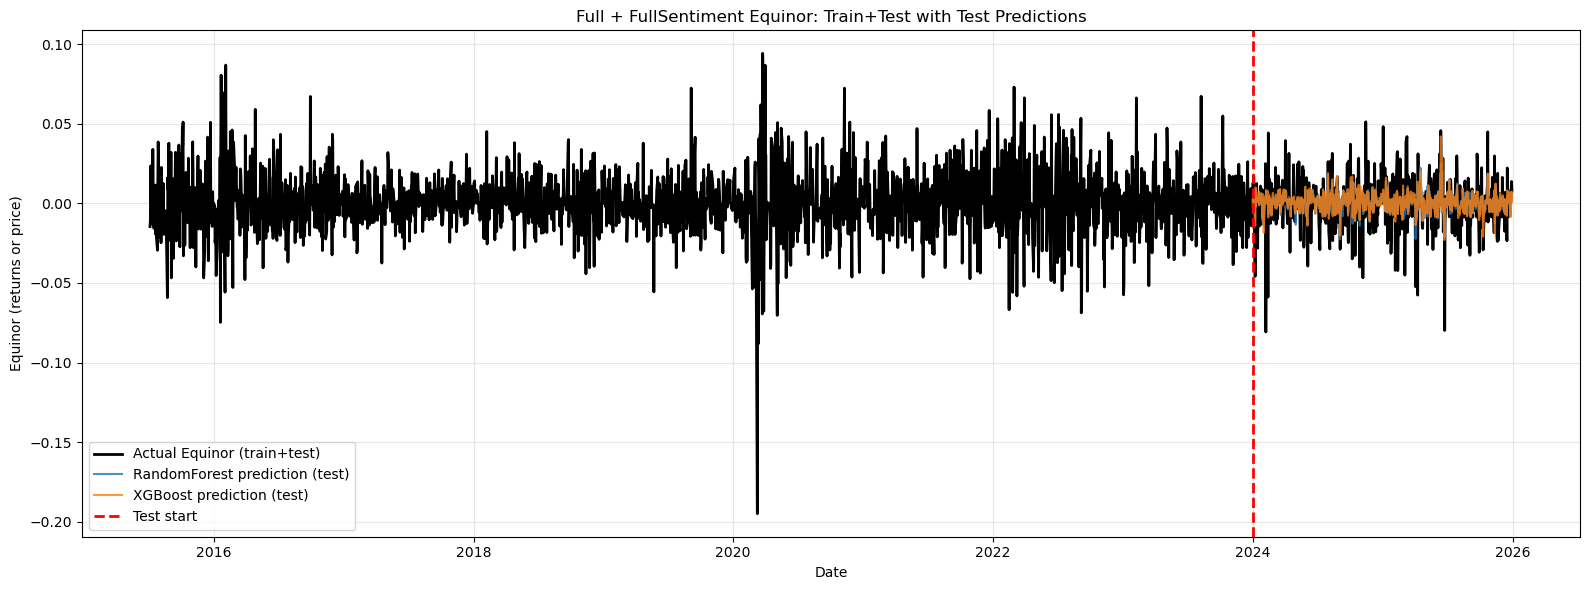

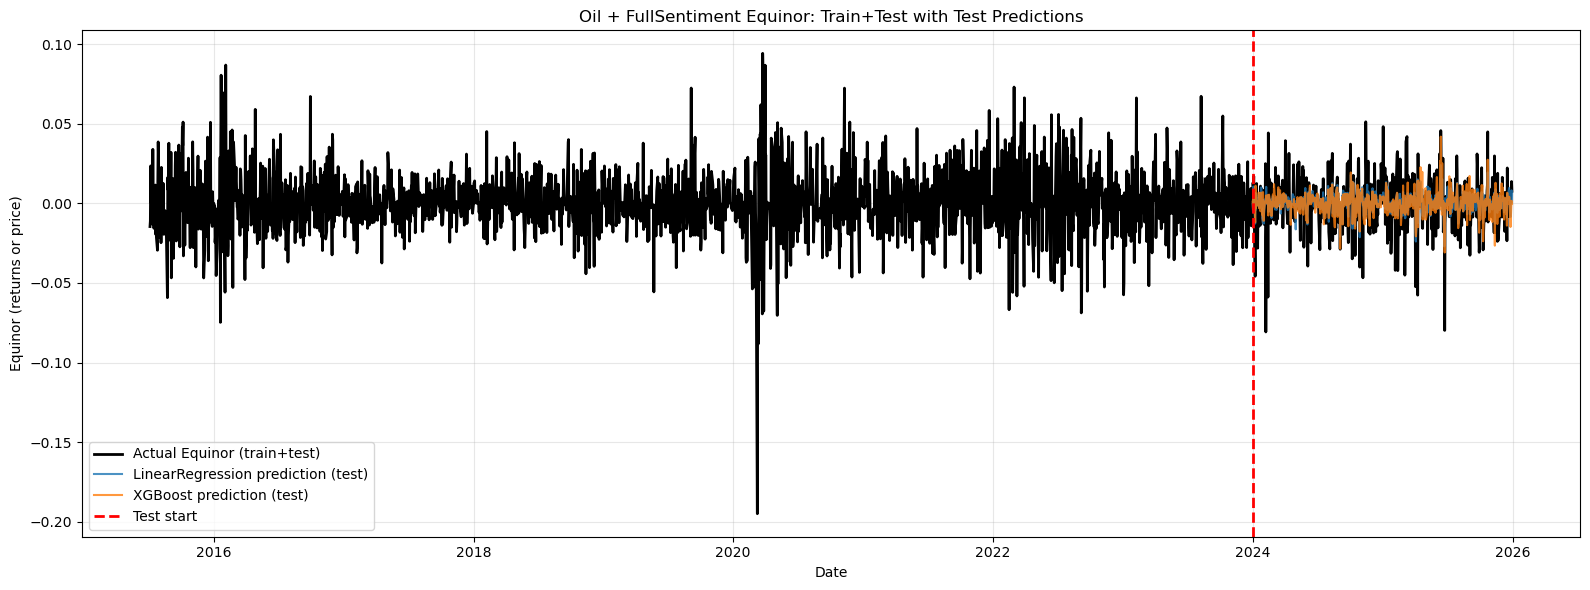

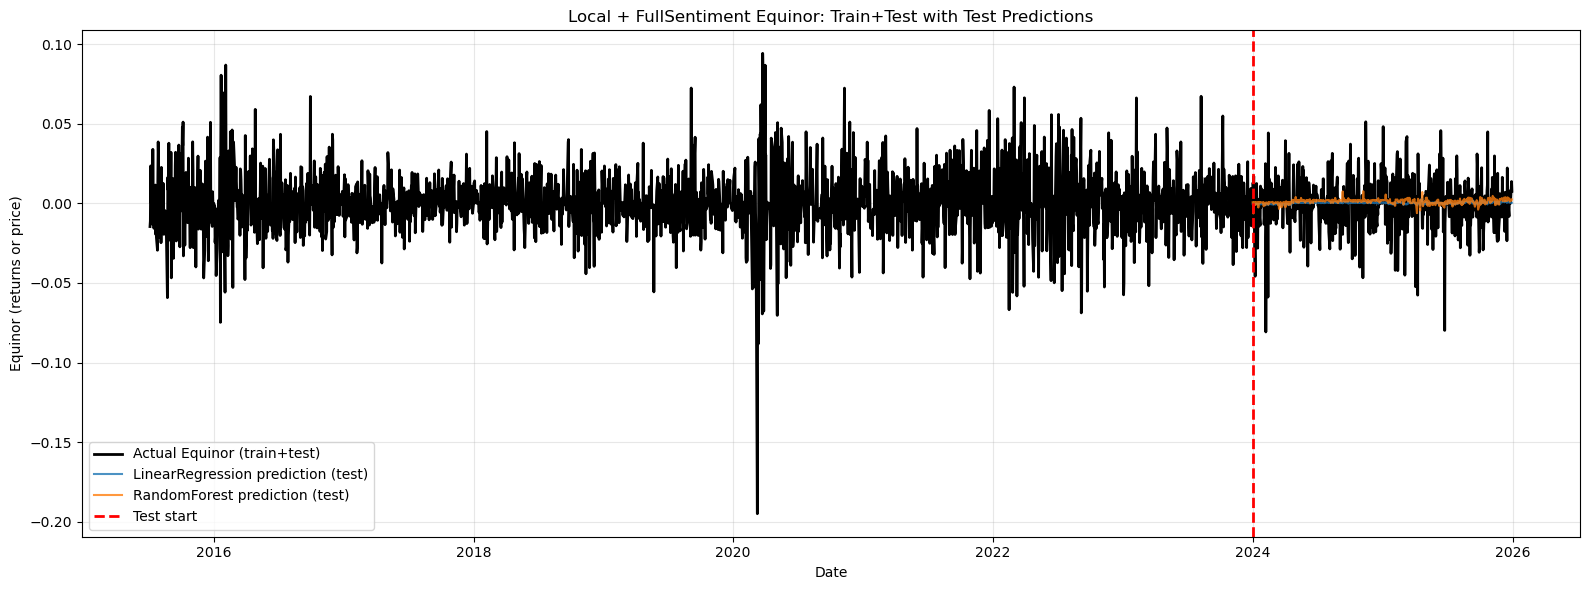

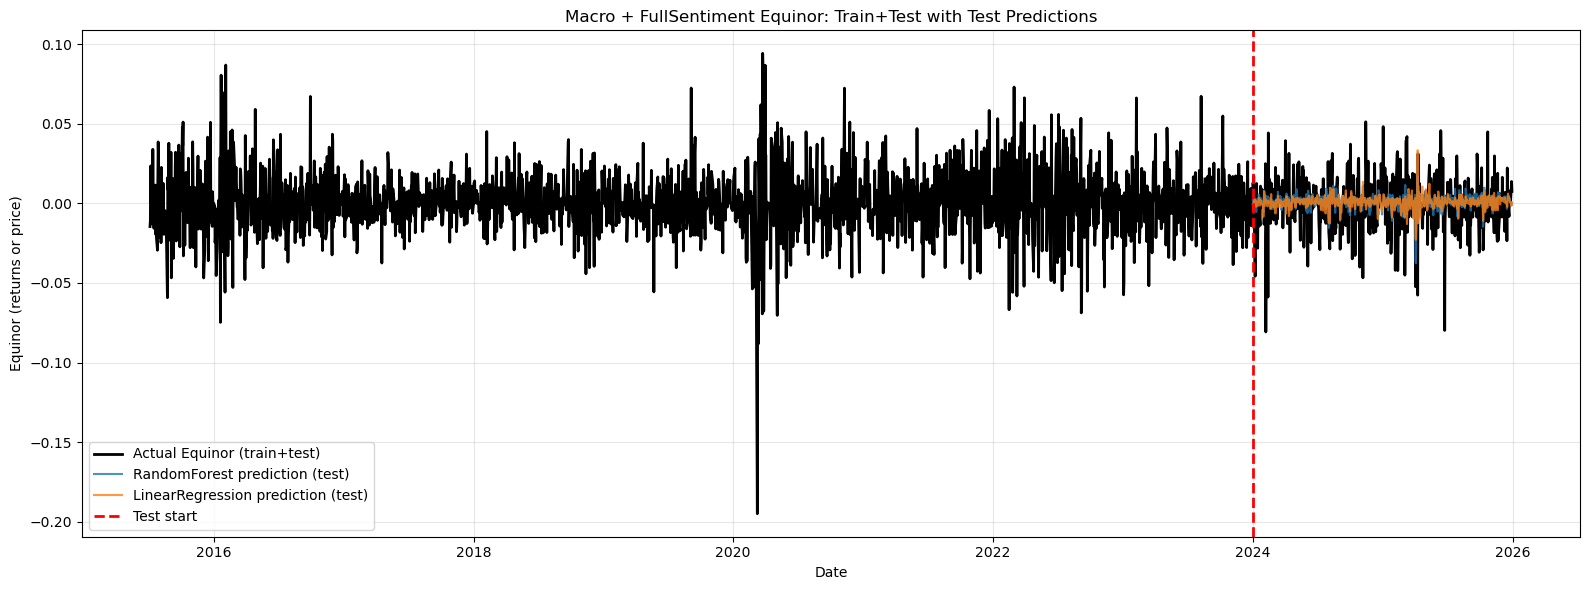

In [50]:
# Full features + full sentiment
plot_full_with_test_preds(
    results_fulldf_fullsenti,
    test_fullpredictions_fullsenti,
    y_fulltrain_fullsenti,
    y_fulltest_fullsenti,
    title_prefix="Full + FullSentiment",
    top_n=2
)

# Oil-only + full sentiment
plot_full_with_test_preds(
    results_oildf_fullsenti,
    test_oilpredictions_fullsenti,
    y_oiltrain_fullsenti,
    y_oiltest_fullsenti,
    title_prefix="Oil + FullSentiment",
    top_n=2
)

# Local-only + full sentiment
plot_full_with_test_preds(
    results_localdf_fullsenti,
    test_localpredictions_fullsenti,
    y_localtrain_fullsenti,
    y_localtest_fullsenti,
    title_prefix="Local + FullSentiment",
    top_n=2
)

# Macro-only + full sentiment
plot_full_with_test_preds(
    results_macrodf_fullsenti,
    test_macropredictions_fullsenti,
    y_macrotrain_fullsenti,
    y_macrotest_fullsenti,
    title_prefix="Macro + FullSentiment",
    top_n=2
)


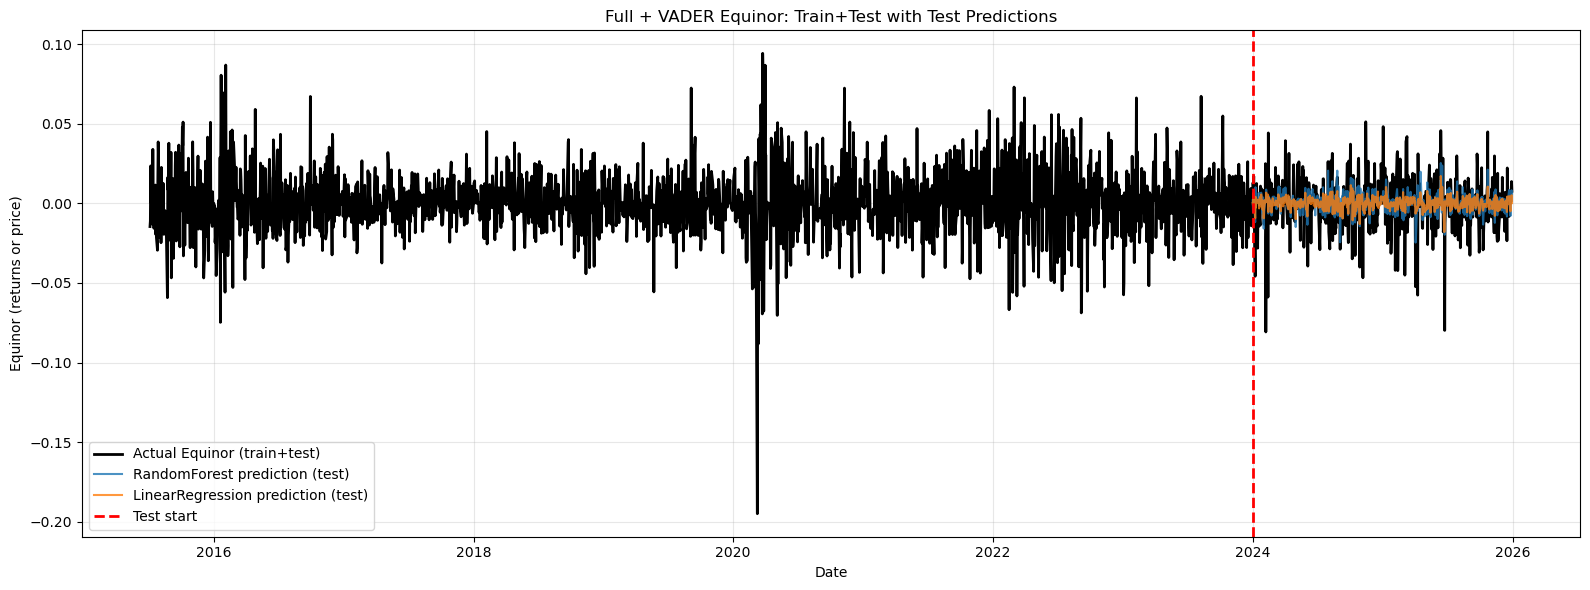

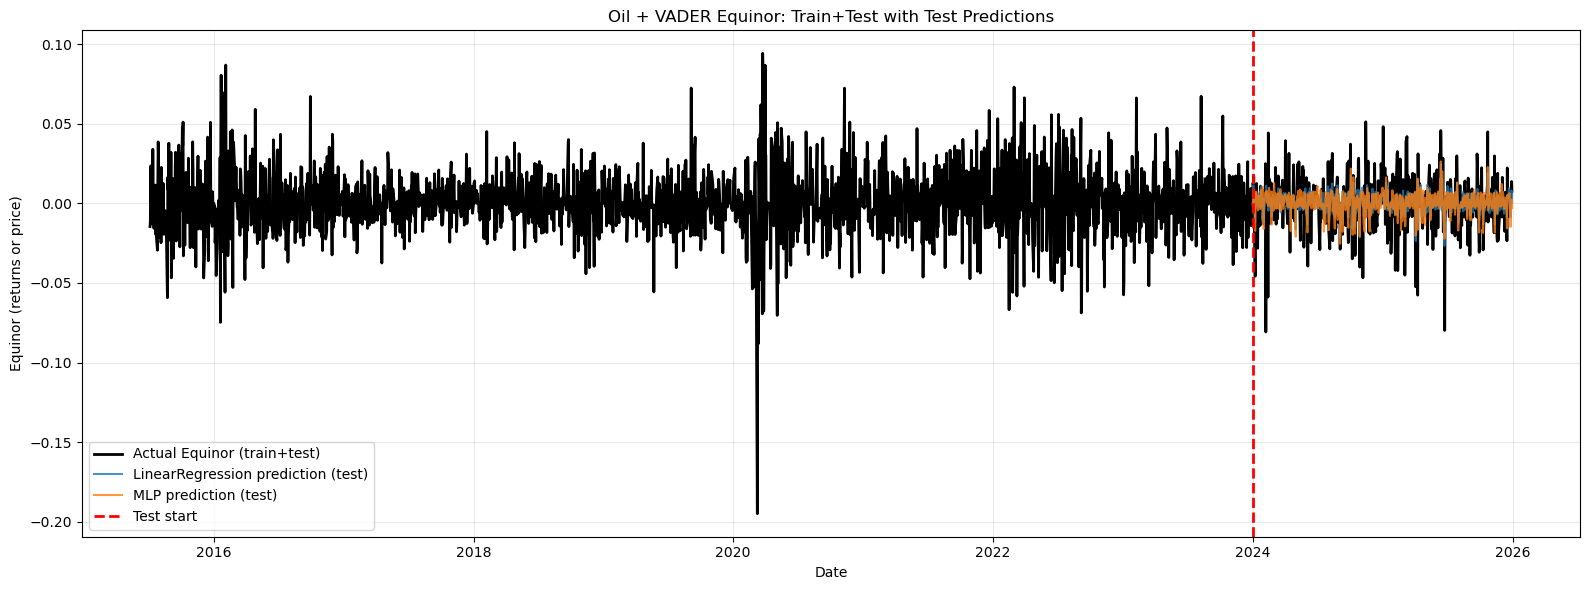

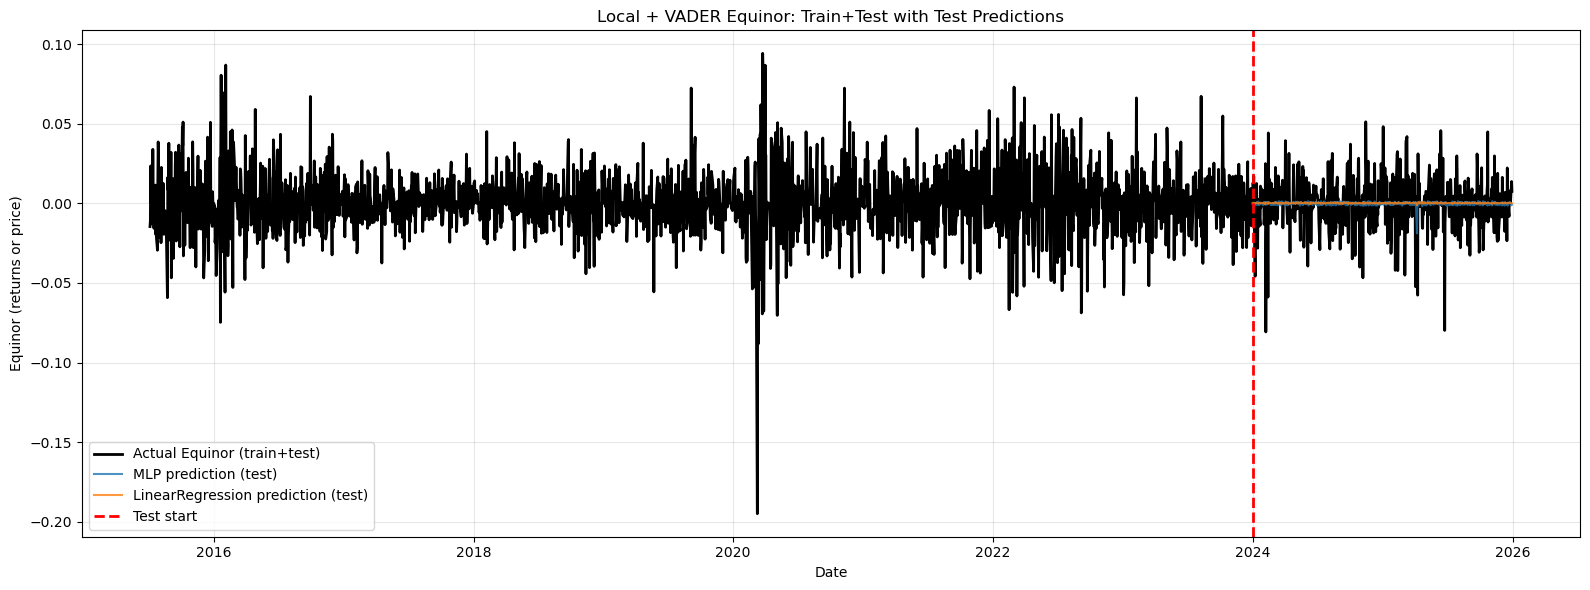

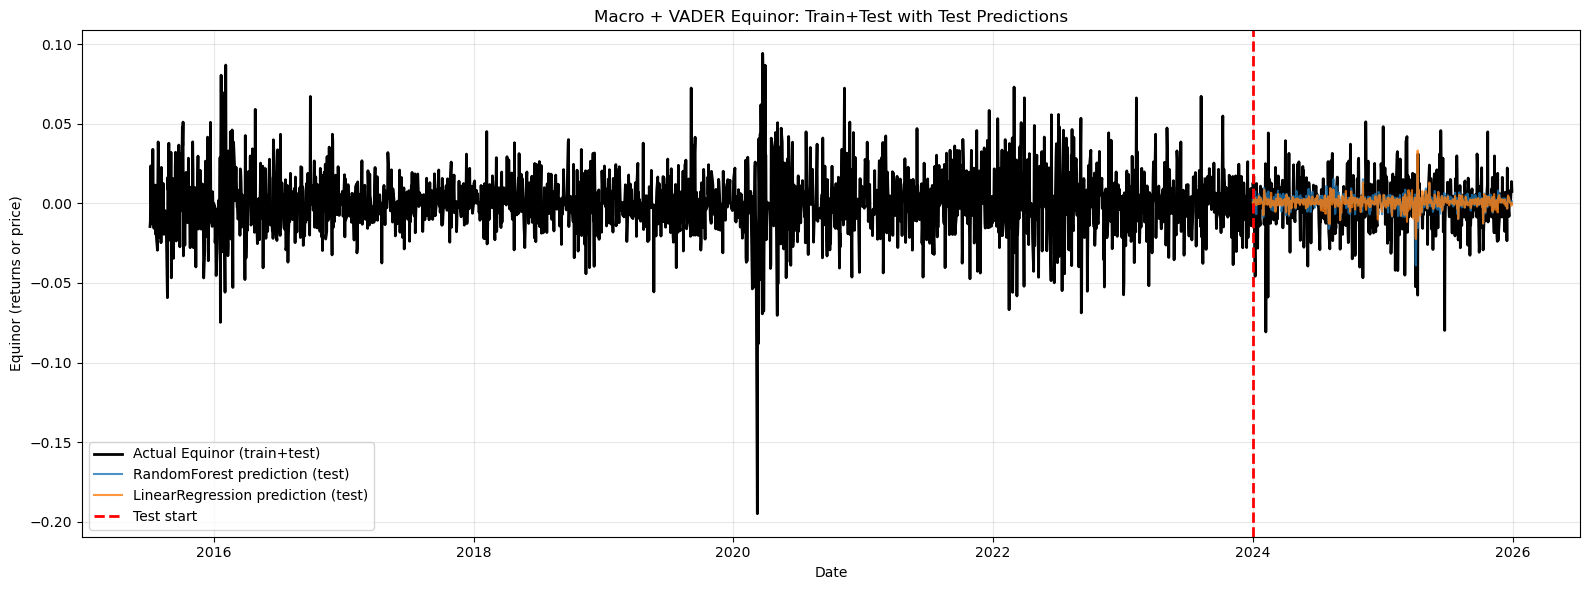

In [51]:
# VADER-only
plot_full_with_test_preds(
    results_fulldf_vader,
    test_fullpredictions_vader,
    y_fulltrain_vader,
    y_fulltest_vader,
    title_prefix="Full + VADER",
    top_n=2
)

plot_full_with_test_preds(
    results_oildf_vader,
    test_oilpredictions_vader,
    y_oiltrain_vader,
    y_oiltest_vader,
    title_prefix="Oil + VADER",
    top_n=2
)

plot_full_with_test_preds(
    results_localdf_vader,
    test_localpredictions_vader,
    y_localtrain_vader,
    y_localtest_vader,
    title_prefix="Local + VADER",
    top_n=2
)

plot_full_with_test_preds(
    results_macrodf_vader,
    test_macropredictions_vader,
    y_macrotrain_vader,
    y_macrotest_vader,
    title_prefix="Macro + VADER",
    top_n=2
)


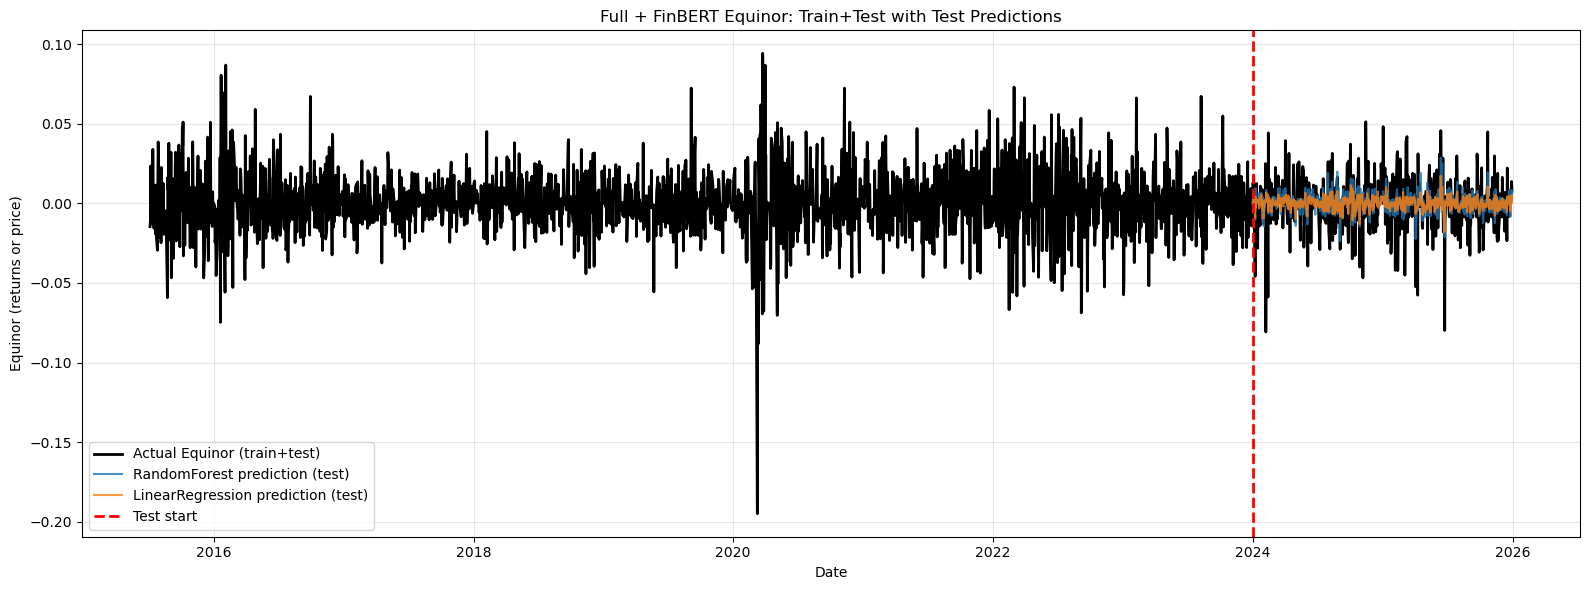

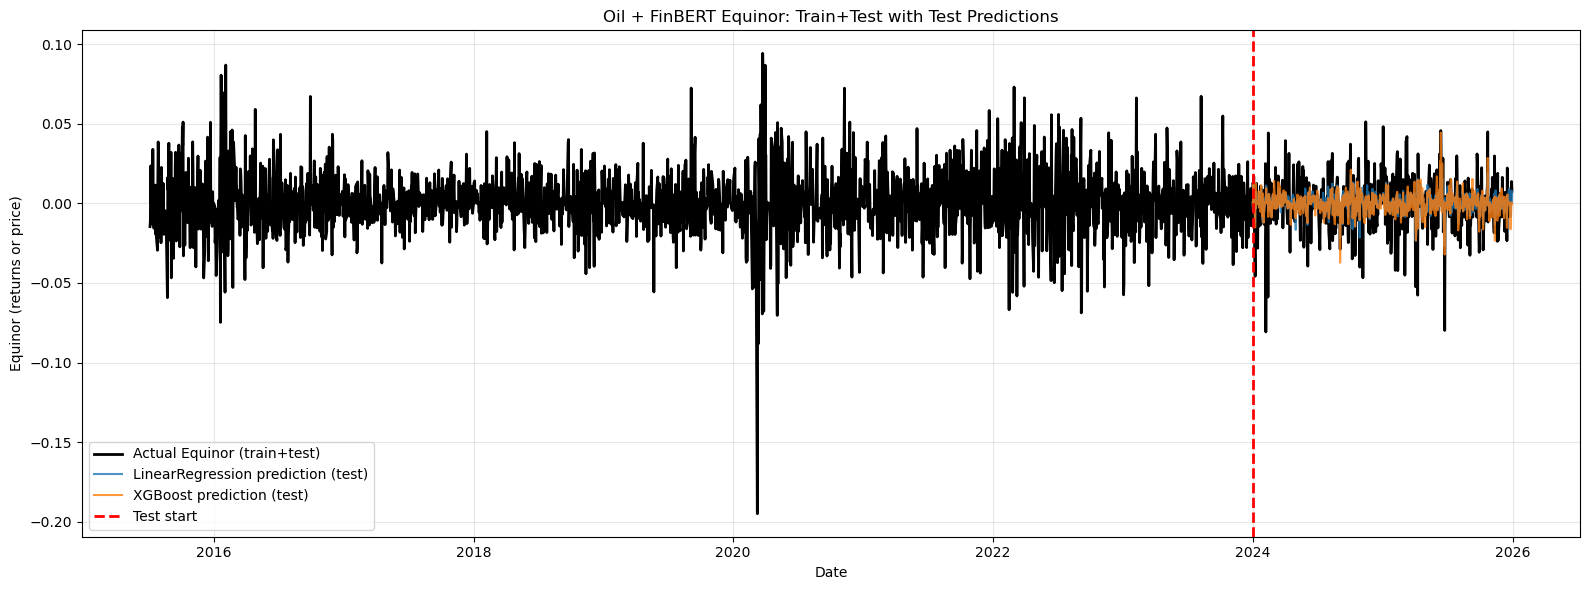

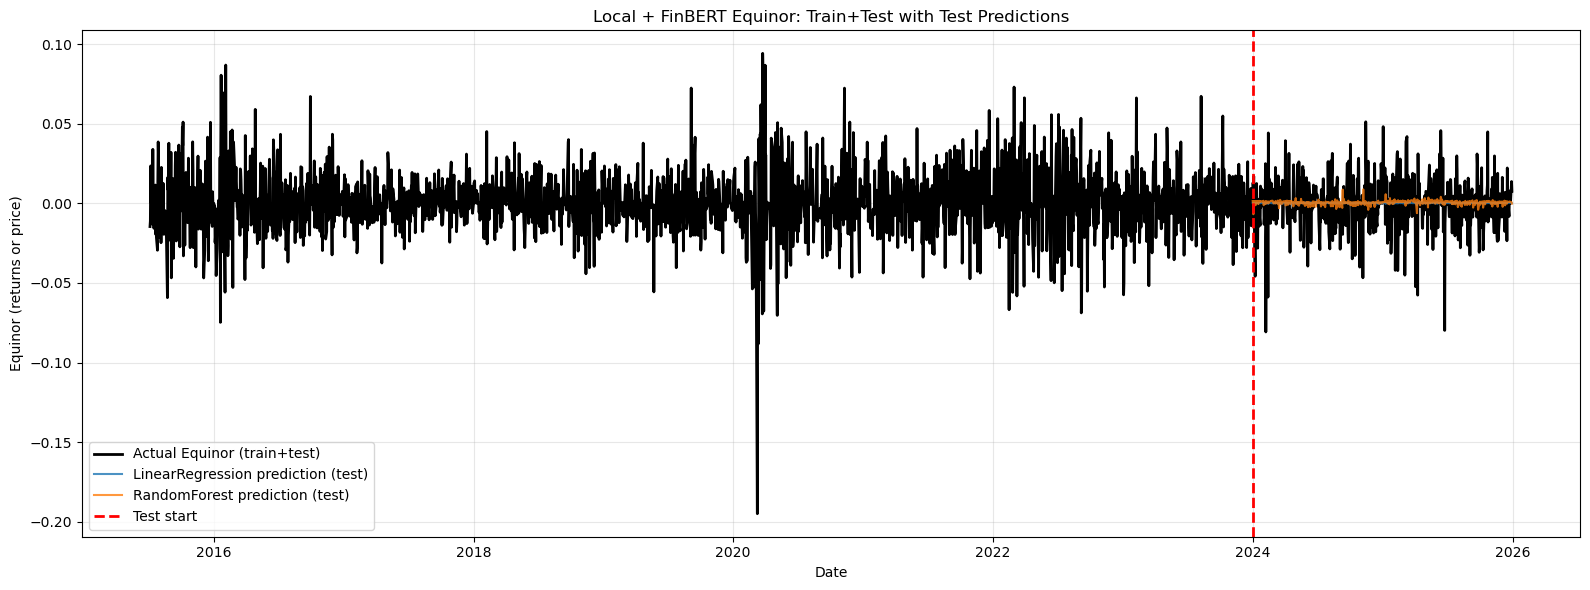

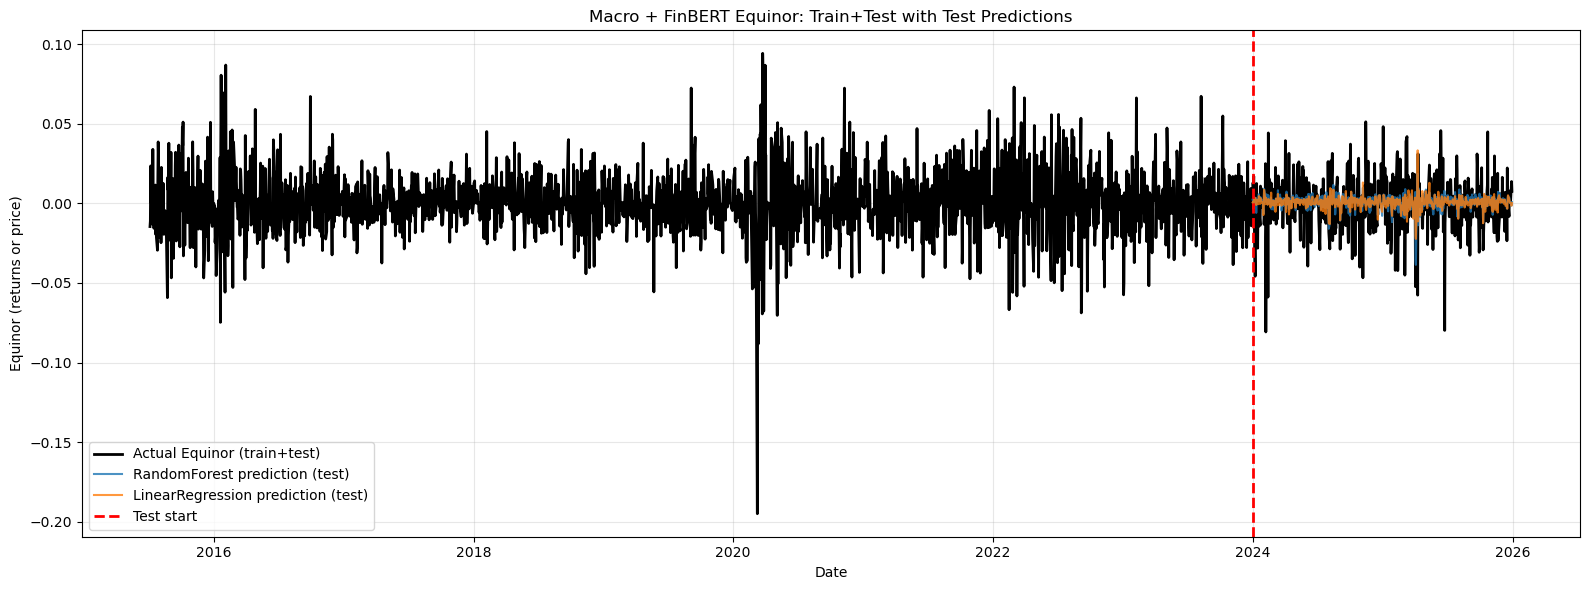

In [52]:
# FinBERT-only
plot_full_with_test_preds(
    results_fulldf_finbert,
    test_fullpredictions_finbert,
    y_fulltrain_finbert,
    y_fulltest_finbert,
    title_prefix="Full + FinBERT",
    top_n=2
)

plot_full_with_test_preds(
    results_oildf_finbert,
    test_oilpredictions_finbert,
    y_oiltrain_finbert,
    y_oiltest_finbert,
    title_prefix="Oil + FinBERT",
    top_n=2
)

plot_full_with_test_preds(
    results_localdf_finbert,
    test_localpredictions_finbert,
    y_localtrain_finbert,
    y_localtest_finbert,
    title_prefix="Local + FinBERT",
    top_n=2
)

plot_full_with_test_preds(
    results_macrodf_finbert,
    test_macropredictions_finbert,
    y_macrotrain_finbert,
    y_macrotest_finbert,
    title_prefix="Macro + FinBERT",
    top_n=2
)


In [53]:
models_try = {

    "LinearRegression": Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LinearRegression()),  ]),
    
    "RandomForest": RandomForestRegressor(
        n_estimators=400,
        max_depth=8,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ),
    
    "XGBoost": XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=4,
        subsample=0.9,
        colsample_bytree=0.9,
        random_state=42,
        n_jobs=-1
    ),
    
    "LightGBM": LGBMRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=5,
        num_leaves=31,
        random_state=42
    ),
    
    "MLP": Pipeline([
    ("scaler", StandardScaler()), 
    ("mlp", MLPRegressor(
        # Smaller layers to prevent overfitting on 7 features
        hidden_layer_sizes=(32, 16), 
        activation="relu",
        # Alpha is L2 regularization - higher values (0.1+) 
        # force the model to be 'simpler' and less noisy
        alpha=0.1, 
        # Learning rate initialization
        learning_rate_init=0.001,
        # Early stopping is critical: it stops training 
        # when the validation score stops improving
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        max_iter=2000, 
        random_state=42
        ))
    ])
}

In [54]:
results_fulldf_vader, test_fullpredictions_vader = run_models(
    X_fulltrain_vader, X_fulltest_vader, y_fulltrain_vader, y_fulltest_vader, models_try
)
results_oildf_vader, test_oilpredictions_vader = run_models(
    X_oiltrain_vader, X_oiltest_vader, y_oiltrain_vader, y_oiltest_vader, models_try
)
results_localdf_vader, test_localpredictions_vader = run_models(
    X_localtrain_vader, X_localtest_vader, y_localtrain_vader, y_localtest_vader, models_try
)
results_macrodf_vader, test_macropredictions_vader = run_models(
    X_macrotrain_vader, X_macrotest_vader, y_macrotrain_vader, y_macrotest_vader, models_try
)

Fitting & evaluating models...
LinearRegression: R²=0.1092, RMSE=0.015558, MAE=0.011320, HitRatio=0.5530
RandomForest: R²=0.1276, RMSE=0.015397, MAE=0.011293, HitRatio=0.5511
XGBoost: R²=0.1001, RMSE=0.015637, MAE=0.011388, HitRatio=0.5684
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000129 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1785
[LightGBM] [Info] Number of data points in the train set: 2213, number of used features: 7
[LightGBM] [Info] Start training from score 0.000552
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with p

In [55]:
print("\nBest Models for Equinor (Full sentiment features) with Full features:")
print(results_fulldf_vader)
print("\nBest Models for Equinor (Full sentiment features) with only macro features:")
print(results_macrodf_vader)
print("\nBest Models for Equinor (Full sentiment features): with only local features")
print(results_localdf_vader)
print("\nBest Models for Equinor (Full sentiment features):with only oil features")
print(results_oildf_vader)


Best Models for Equinor (Full sentiment features) with Full features:
              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.011293   0.015397  0.000237  0.127596   0.551060   
1  LinearRegression  0.011320   0.015558  0.000242  0.109204   0.552987   
2           XGBoost  0.011388   0.015637  0.000245  0.100083   0.568401   
3               MLP  0.011415   0.015639  0.000245  0.099853   0.560694   
4          LightGBM  0.011467   0.015642  0.000245  0.099599   0.562620   

   Features  
0         7  
1         7  
2         7  
3         7  
4         7  

Best Models for Equinor (Full sentiment features) with only macro features:
              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.012102   0.016854  0.000284 -0.045396   0.506744   
1  LinearRegression  0.012107   0.017019  0.000290 -0.065969   0.493256   
2          LightGBM  0.012569   0.017337  0.000301 -0.106156   0.495183   
3           XGBoo

In [56]:
folds = [
    {"train_start": "2015-01-01", "train_end": "2018-12-31", "test_start": "2019-01-01", "test_end": "2019-12-31"},
    {"train_start": "2016-01-01", "train_end": "2019-12-31", "test_start": "2020-01-01", "test_end": "2020-12-31"},
    {"train_start": "2017-01-01", "train_end": "2020-12-31", "test_start": "2021-01-01", "test_end": "2021-12-31"},
    {"train_start": "2018-01-01", "train_end": "2021-12-31", "test_start": "2022-01-01", "test_end": "2022-12-31"},
    {"train_start": "2019-01-01", "train_end": "2022-12-31", "test_start": "2023-01-01", "test_end": "2023-12-31"},
    {"train_start": "2020-01-01", "train_end": "2023-12-31", "test_start": "2024-01-01", "test_end": "2024-12-31"},
    {"train_start": "2021-01-01", "train_end": "2024-12-31", "test_start": "2025-01-01", "test_end": "2025-12-31"},
]


In [57]:
def regression_metrics_with_hitratio(y_true, y_pred, ignore_zero=True):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    
    actual_sign = np.sign(y_true)
    pred_sign = np.sign(y_pred)
    
    if ignore_zero:
        mask = actual_sign != 0
        if mask.sum() > 0:
            hit_ratio = (actual_sign[mask] == pred_sign[mask]).mean()
        else:
            hit_ratio = np.nan
    else:
        hit_ratio = (actual_sign == pred_sign).mean()
    
    return rmse, mae, r2, hit_ratio


In [58]:
def walk_forward_validation_dates(X, y, models, folds, target_col="Equinor"):
    results = []
    predictions = {}

    # Initialize prediction containers
    for model_name in list(models.keys()) + ["NaiveZero", "NaiveLast"]:
        predictions[model_name] = []

    for fold_idx, f in enumerate(folds, start=1):
        # Slice by date
        X_train = X.loc[f["train_start"]:f["train_end"]]
        y_train = y.loc[f["train_start"]:f["train_end"]]
        X_test  = X.loc[f["test_start"]:f["test_end"]]
        y_test  = y.loc[f["test_start"]:f["test_end"]]

        if len(X_test) == 0 or len(X_train) == 0:
            continue  

        # --- NaiveZero ---
        naive_zero_pred = np.zeros(len(y_test))
        rmse, mae, r2, hit_ratio = regression_metrics_with_hitratio(y_test.values, naive_zero_pred)
        results.append({
            "fold": fold_idx,
            "model": "NaiveZero",
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2,
            "Hit_Ratio": hit_ratio,
        })
        predictions["NaiveZero"].append(pd.DataFrame({
            "y_true": y_test.values,
            "y_pred": naive_zero_pred,
        }, index=y_test.index))

        # --- NaiveLast ---
        if f"{target_col}_lag1" in X_test.columns:
            naive_last_pred = X_test[f"{target_col}_lag1"].values
        else:
            naive_last_pred = y.shift(1).loc[y_test.index].fillna(0).values

        rmse, mae, r2, hit_ratio = regression_metrics_with_hitratio(y_test.values, naive_last_pred)
        results.append({
            "fold": fold_idx,
            "model": "NaiveLast",
            "RMSE": rmse,
            "MAE": mae,
            "R2": r2,
            "Hit_Ratio": hit_ratio,
        })
        predictions["NaiveLast"].append(pd.DataFrame({
            "y_true": y_test.values,
            "y_pred": naive_last_pred,
        }, index=y_test.index))

        # --- ML models ---
        for model_name, model in models.items():
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            rmse, mae, r2, hit_ratio = regression_metrics_with_hitratio(y_test.values, y_pred)

            results.append({
                "fold": fold_idx,
                "model": model_name,
                "RMSE": rmse,
                "MAE": mae,
                "R2": r2,
                "Hit_Ratio": hit_ratio,
            })

            predictions[model_name].append(pd.DataFrame({
                "y_true": y_test.values,
                "y_pred": y_pred,
            }, index=y_test.index))

    results_df = pd.DataFrame(results)
    return results_df, predictions


In [59]:
X_fullsenti = merged_df.drop('Equinor', axis=1)     
y = merged_df['Equinor']   

In [60]:
results_fullsenti, preds_fullsenti = walk_forward_validation_dates(
    X_fullsenti,
    y,
    models,
    folds=folds,
    target_col="Equinor"   
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000116 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 2125
[LightGBM] [Info] Number of data points in the train set: 911, number of used features: 9
[LightGBM] [Info] Start training from score 0.000498
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

In [64]:
summary_fullsenti = results_fullsenti.groupby("model")[["RMSE", "MAE", "R2", "Hit_Ratio"]].mean().sort_values("R2", ascending=False)
print(summary_fullsenti)

                      RMSE       MAE        R2  Hit_Ratio
model                                                    
LinearRegression  0.015447  0.011452  0.311182   0.680971
RandomForest      0.016215  0.011816  0.262711   0.664430
XGBoost           0.016496  0.012115  0.238675   0.658731
LightGBM          0.016696  0.012255  0.217840   0.653082
MLP               0.017229  0.012250  0.194236   0.657549
NaiveZero         0.019157  0.013850 -0.002536   0.000000
NaiveLast         0.027388  0.020404 -1.048720   0.485851


In [65]:
X_fullsenti = merged_df.drop('Equinor', axis=1)     
y = merged_df['Equinor']  

In [66]:
# === 1) Build full X,y for each feature set (no train/test split here) ===

# Oil + sentiment: keep oil, sentiment, drop local + macro
X_oil_fullsenti = merged_df.drop(
    columns=["Equinor", "OSEBX", "USDNOK", "SP500", "US10Y", "VIX"],
    errors="ignore"
)
y_oil_fullsenti = merged_df["Equinor"]

# Local + sentiment: keep local (OSEBX, USDNOK), sentiment, drop macro + oil
X_local_fullsenti = merged_df.drop(
    columns=["Equinor", "SP500", "US10Y", "VIX", "Brent_oil", "WTI_oil"],
    errors="ignore"
)
y_local_fullsenti = merged_df["Equinor"]

# Macro + sentiment: keep SP500, US10Y, VIX, sentiment, drop local + oil
X_macro_fullsenti = merged_df.drop(
    columns=["Equinor", "OSEBX", "USDNOK", "Brent_oil", "WTI_oil"],
    errors="ignore"
)
y_macro_fullsenti = merged_df["Equinor"]

X_full_fullsenti = merged_df.drop(columns=["Equinor"], errors="ignore")
y_full_fullsenti = merged_df["Equinor"]


In [67]:
results_oil_wf, preds_oil_wf = walk_forward_validation_dates(
    X_oil_fullsenti,
    y_oil_fullsenti,
    models,
    folds=folds,
    target_col="Equinor"
)

results_local_wf, preds_local_wf = walk_forward_validation_dates(
    X_local_fullsenti,
    y_local_fullsenti,
    models,
    folds=folds,
    target_col="Equinor"
)

results_macro_wf, preds_macro_wf = walk_forward_validation_dates(
    X_macro_fullsenti,
    y_macro_fullsenti,
    models,
    folds=folds,
    target_col="Equinor"
)

results_full_wf, preds_full_wf = walk_forward_validation_dates(
    X_full_fullsenti,
    y_full_fullsenti,
    models,
    folds=folds,
    target_col="Equinor"
)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000062 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 850
[LightGBM] [Info] Number of data points in the train set: 911, number of used features: 4
[LightGBM] [Info] Start training from score 0.000498
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

In [68]:
# Oil + VADER
X_oil_vader = merged_df.drop(
    columns=["Equinor", "OSEBX", "USDNOK", "SP500", "US10Y", "VIX", "finbert_sentiment"],
    errors="ignore"
)
y_oil_vader = merged_df["Equinor"]

# Local + VADER
X_local_vader = merged_df.drop(
    columns=["Equinor", "SP500", "US10Y", "VIX", "Brent_oil", "WTI_oil", "finbert_sentiment"],
    errors="ignore"
)
y_local_vader = merged_df["Equinor"]

# Macro + VADER
X_macro_vader = merged_df.drop(
    columns=["Equinor", "OSEBX", "USDNOK", "Brent_oil", "WTI_oil", "finbert_sentiment"],
    errors="ignore"
)
y_macro_vader = merged_df["Equinor"]

# Full + VADER
X_full_vader = merged_df.drop(
    columns=["Equinor", "finbert_sentiment"],
    errors="ignore"
)
y_full_vader = merged_df["Equinor"]

In [69]:
# Walk‑forward runs (VADER)
results_oil_wf_vader, preds_oil_wf_vader = walk_forward_validation_dates(
    X_oil_vader, y_oil_vader, models, folds=folds, target_col="Equinor"
)

results_local_wf_vader, preds_local_wf_vader = walk_forward_validation_dates(
    X_local_vader, y_local_vader, models, folds=folds, target_col="Equinor"
)

results_macro_wf_vader, preds_macro_wf_vader = walk_forward_validation_dates(
    X_macro_vader, y_macro_vader, models, folds=folds, target_col="Equinor"
)

results_full_wf_vader, preds_full_wf_vader = walk_forward_validation_dates(
    X_full_vader, y_full_vader, models, folds=folds, target_col="Equinor"
)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000125 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 601
[LightGBM] [Info] Number of data points in the train set: 911, number of used features: 3
[LightGBM] [Info] Start training from score 0.000498
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

In [70]:
# ============== FINBERT ONLY ==============

# Oil + FinBERT
X_oil_finbert = merged_df.drop(
    columns=["Equinor", "OSEBX", "USDNOK", "SP500", "US10Y", "VIX", "vader_sentiment"],
    errors="ignore"
)
y_oil_finbert = merged_df["Equinor"]

# Local + FinBERT
X_local_finbert = merged_df.drop(
    columns=["Equinor", "SP500", "US10Y", "VIX", "Brent_oil", "WTI_oil", "vader_sentiment"],
    errors="ignore"
)
y_local_finbert = merged_df["Equinor"]

# Macro + FinBERT
X_macro_finbert = merged_df.drop(
    columns=["Equinor", "OSEBX", "USDNOK", "Brent_oil", "WTI_oil", "vader_sentiment"],
    errors="ignore"
)
y_macro_finbert = merged_df["Equinor"]

# Full + FinBERT
X_full_finbert = merged_df.drop(
    columns=["Equinor", "vader_sentiment"],
    errors="ignore"
)
y_full_finbert = merged_df["Equinor"]



In [71]:
# Walk‑forward runs (FinBERT)
results_oil_wf_finbert, preds_oil_wf_finbert = walk_forward_validation_dates(
    X_oil_finbert, y_oil_finbert, models, folds=folds, target_col="Equinor"
)

results_local_wf_finbert, preds_local_wf_finbert = walk_forward_validation_dates(
    X_local_finbert, y_local_finbert, models, folds=folds, target_col="Equinor"
)

results_macro_wf_finbert, preds_macro_wf_finbert = walk_forward_validation_dates(
    X_macro_finbert, y_macro_finbert, models, folds=folds, target_col="Equinor"
)

results_full_wf_finbert, preds_full_wf_finbert = walk_forward_validation_dates(
    X_full_finbert, y_full_finbert, models, folds=folds, target_col="Equinor"
)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.003774 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 759
[LightGBM] [Info] Number of data points in the train set: 911, number of used features: 3
[LightGBM] [Info] Start training from score 0.000498
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, bes

In [72]:
summary_fullsenti = results_fullsenti.groupby("model")[["RMSE", "MAE", "R2", "Hit_Ratio"]].mean().sort_values("R2", ascending=False)
print(summary_fullsenti)
summary_oil = results_fullsenti.groupby("model")[["RMSE", "MAE", "R2", "Hit_Ratio"]].mean().sort_values("R2", ascending=False)
print(summary_fullsenti)
summary_fullsenti = results_fullsenti.groupby("model")[["RMSE", "MAE", "R2", "Hit_Ratio"]].mean().sort_values("R2", ascending=False)
print(summary_fullsenti)
summary_fullsenti = results_fullsenti.groupby("model")[["RMSE", "MAE", "R2", "Hit_Ratio"]].mean().sort_values("R2", ascending=False)
print(summary_fullsenti)

                      RMSE       MAE        R2  Hit_Ratio
model                                                    
LinearRegression  0.015447  0.011452  0.311182   0.680971
RandomForest      0.016215  0.011816  0.262711   0.664430
XGBoost           0.016496  0.012115  0.238675   0.658731
LightGBM          0.016696  0.012255  0.217840   0.653082
MLP               0.017229  0.012250  0.194236   0.657549
NaiveZero         0.019157  0.013850 -0.002536   0.000000
NaiveLast         0.027388  0.020404 -1.048720   0.485851
                      RMSE       MAE        R2  Hit_Ratio
model                                                    
LinearRegression  0.015447  0.011452  0.311182   0.680971
RandomForest      0.016215  0.011816  0.262711   0.664430
XGBoost           0.016496  0.012115  0.238675   0.658731
LightGBM          0.016696  0.012255  0.217840   0.653082
MLP               0.017229  0.012250  0.194236   0.657549
NaiveZero         0.019157  0.013850 -0.002536   0.000000
NaiveLast     

In [73]:
def summarize_wf(results_wf: pd.DataFrame, label: str):
    """
    results_wf: long DF from walk_forward_validation_dates (columns: fold, model, RMSE, MAE, R2, Hit_Ratio)
    label: string describing setup, e.g. 'Full+FullSenti', 'Oil+VADER'
    """
    agg = (
        results_wf
        .groupby("model")[["RMSE", "MAE", "R2", "Hit_Ratio"]]
        .mean()
        .reset_index()
    )
    agg["Setup"] = label
    return agg

In [74]:
summaries = []

# Full sentiment
summaries.append(summarize_wf(results_full_wf,  "Full+FullSenti"))
summaries.append(summarize_wf(results_oil_wf,   "Oil+FullSenti"))
summaries.append(summarize_wf(results_local_wf, "Local+FullSenti"))
summaries.append(summarize_wf(results_macro_wf, "Macro+FullSenti"))

# VADER only
summaries.append(summarize_wf(results_full_wf_vader,  "Full+VADER"))
summaries.append(summarize_wf(results_oil_wf_vader,   "Oil+VADER"))
summaries.append(summarize_wf(results_local_wf_vader, "Local+VADER"))
summaries.append(summarize_wf(results_macro_wf_vader, "Macro+VADER"))

# FinBERT only
summaries.append(summarize_wf(results_full_wf_finbert,  "Full+FinBERT"))
summaries.append(summarize_wf(results_oil_wf_finbert,   "Oil+FinBERT"))
summaries.append(summarize_wf(results_local_wf_finbert, "Local+FinBERT"))
summaries.append(summarize_wf(results_macro_wf_finbert, "Macro+FinBERT"))

# ====== Final combined summary ======

all_summary = (
    pd.concat(summaries, ignore_index=True)
    .sort_values(["model", "Setup"])
    .reset_index(drop=True)
)

print(all_summary)

       model      RMSE       MAE        R2  Hit_Ratio            Setup
0   LightGBM  0.016668  0.012215  0.220961   0.652992     Full+FinBERT
1   LightGBM  0.016696  0.012255  0.217840   0.653082   Full+FullSenti
2   LightGBM  0.016683  0.012233  0.219749   0.655360       Full+VADER
3   LightGBM  0.017559  0.012828  0.123515   0.598142    Local+FinBERT
4   LightGBM  0.017595  0.012898  0.119166   0.582074  Local+FullSenti
..       ...       ...       ...       ...        ...              ...
79   XGBoost  0.019363  0.014482 -0.035932   0.549529  Macro+FullSenti
80   XGBoost  0.019470  0.014574 -0.045411   0.546637      Macro+VADER
81   XGBoost  0.018800  0.013716  0.034583   0.608321      Oil+FinBERT
82   XGBoost  0.018651  0.013623  0.049157   0.604244    Oil+FullSenti
83   XGBoost  0.018409  0.013555  0.074932   0.599163        Oil+VADER

[84 rows x 6 columns]


In [75]:
all_summary.to_csv("Model_results.csv")

In [76]:
def plot_wf_top_models(results_wf, preds_wf, y_full, title_prefix="", top_n=2):
    
    # Pick top-N models by mean R2 across folds
    mean_perf = (
        results_wf
        .groupby("model")[["R2"]]
        .mean()
        .sort_values("R2", ascending=False)
    )
    top_models = mean_perf.head(top_n).index.tolist()

    # Concatenate OOS preds per model
    full_oos_preds = {}
    for name in top_models:
        full_oos_preds[name] = (
            pd.concat(preds_wf[name])   # list of DFs -> one DF
            .sort_index()
        )

    # Get first OOS date
    wf_oos = full_oos_preds[top_models[0]]
    test_start_date = wf_oos.index.min()

    # Plot
    plt.figure(figsize=(16, 6))
    plt.plot(
        y_full.index,
        y_full.values,
        label="Actual Equinor (full)",
        color="black",
        linewidth=2,
    )

    for name in top_models:
        plt.plot(
            full_oos_preds[name].index,
            full_oos_preds[name]["y_pred"].values,
            label=f"{name} prediction (OOS)",
            alpha=0.8,
        )

    plt.axvline(
        x=test_start_date,
        color="red",
        linestyle="--",
        linewidth=2,
        label="WF OOS start",
    )

    title = (
        f"Equinor: {title_prefix} – Walk-Forward Predictions (Top {top_n} Models)"
        if title_prefix
        else f"Equinor: Walk-Forward Predictions (Top {top_n} Models)"
    )
    plt.title(title)
    plt.xlabel("Date")
    plt.ylabel("Equinor (returns or price)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


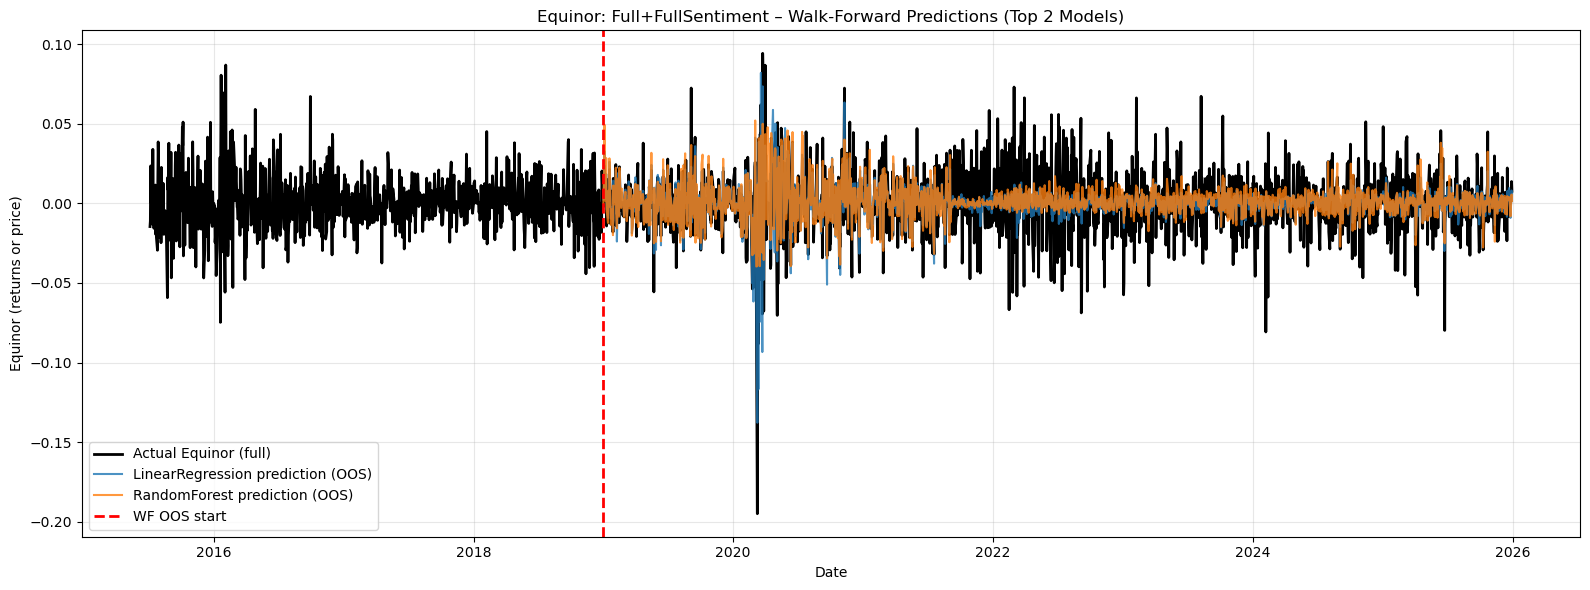

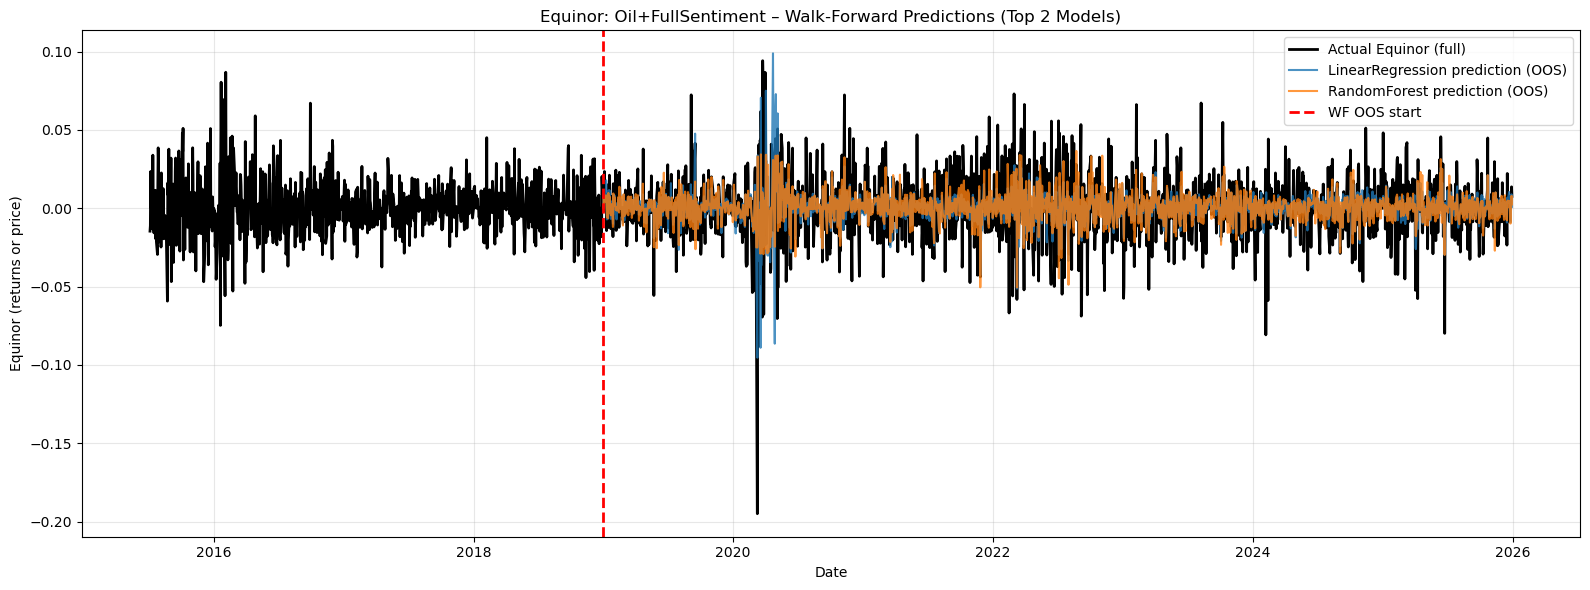

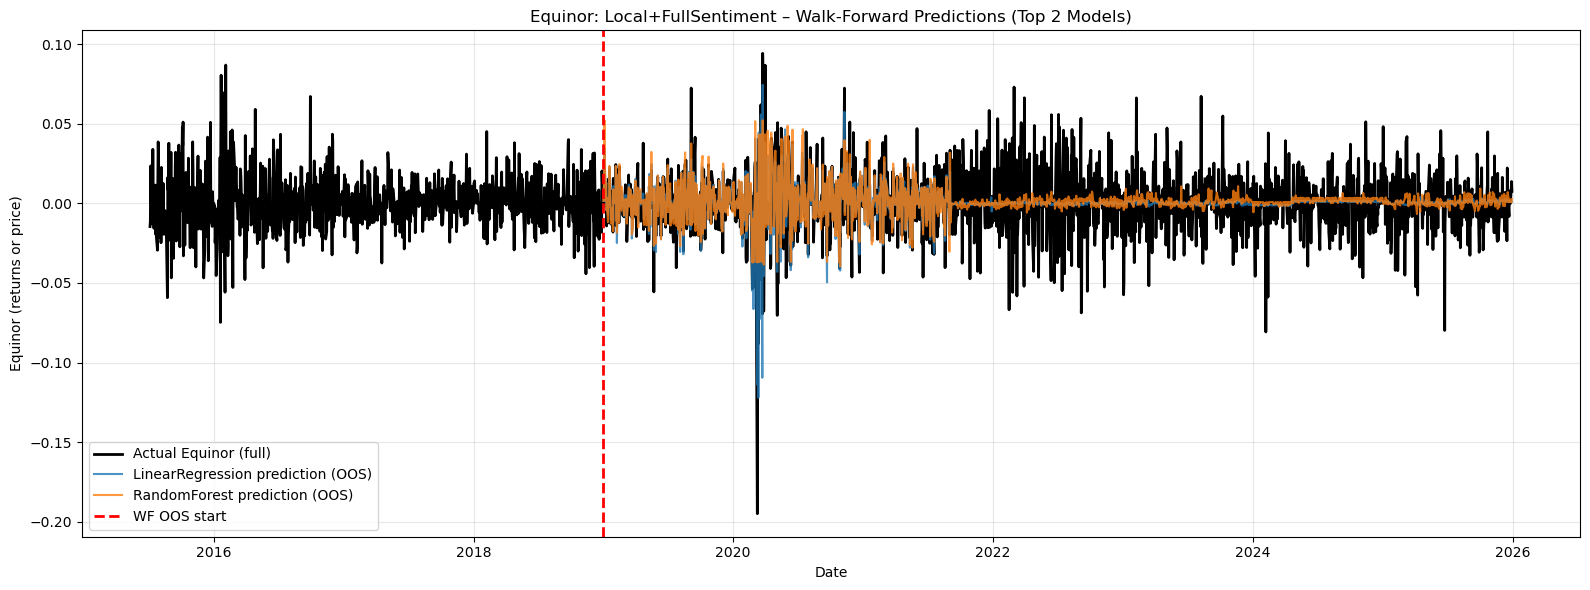

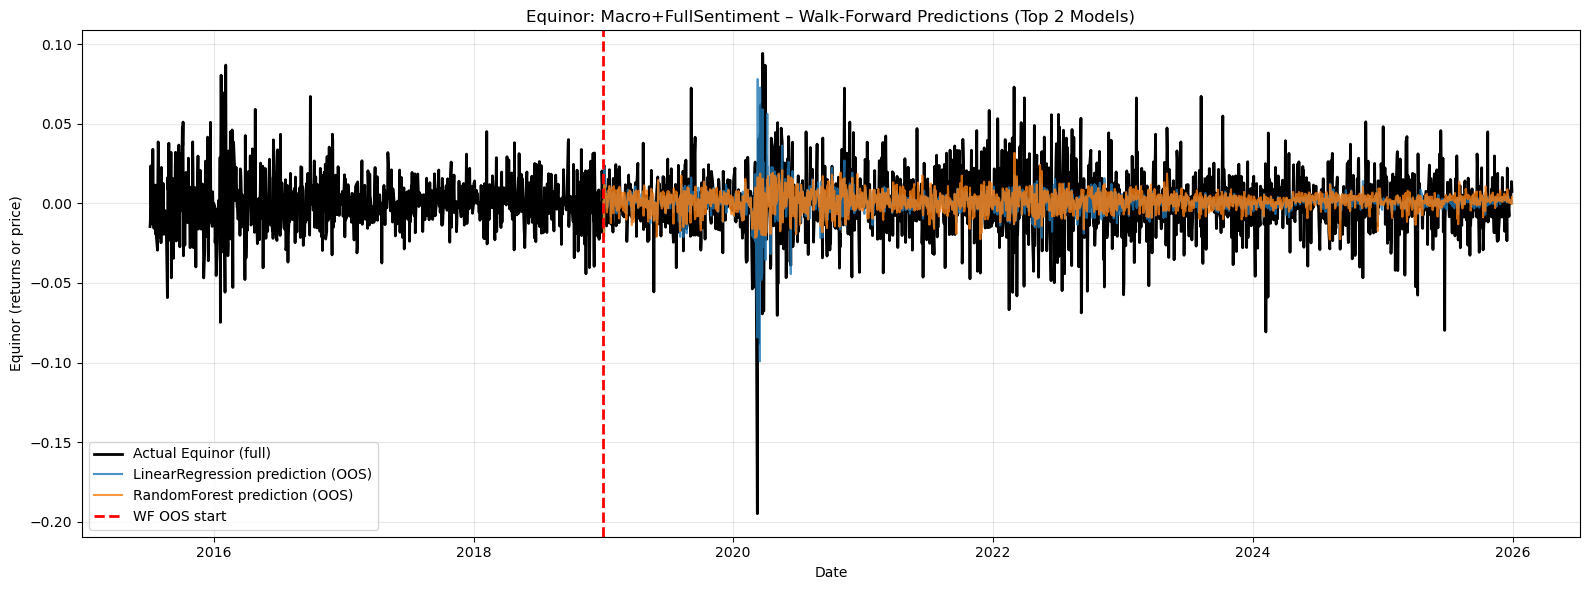

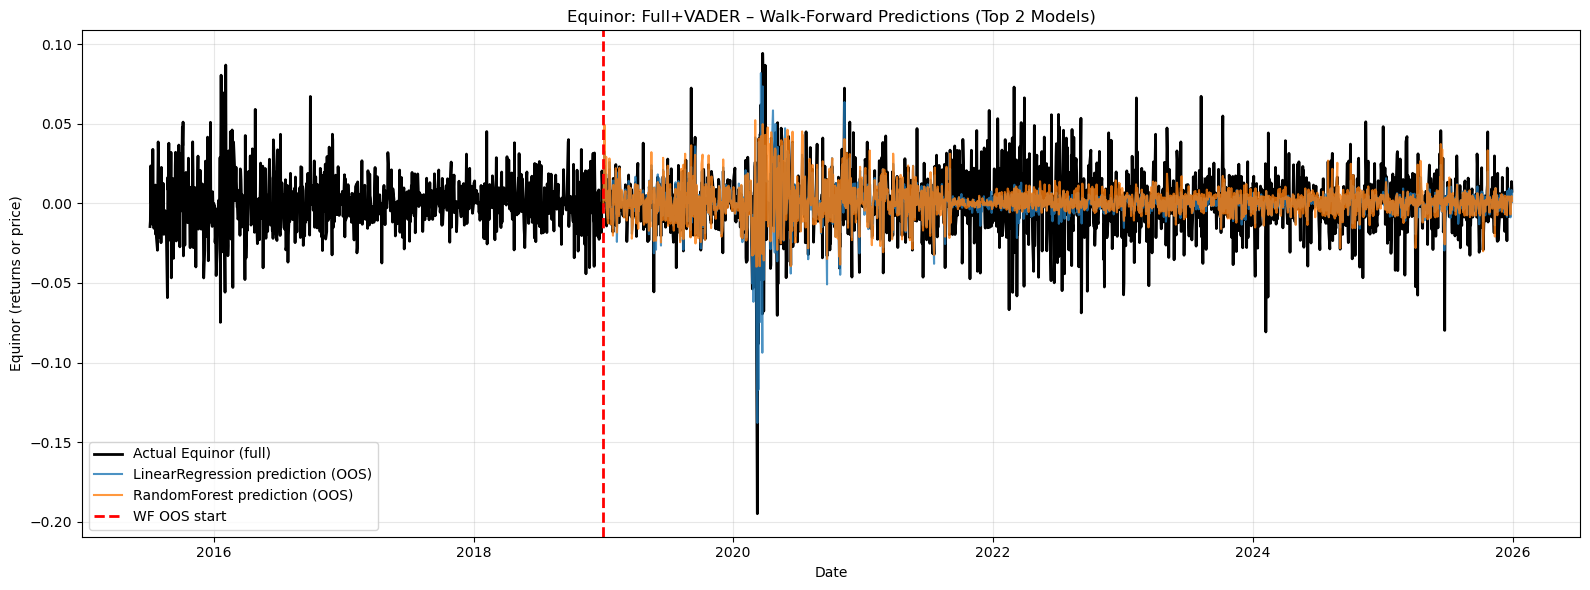

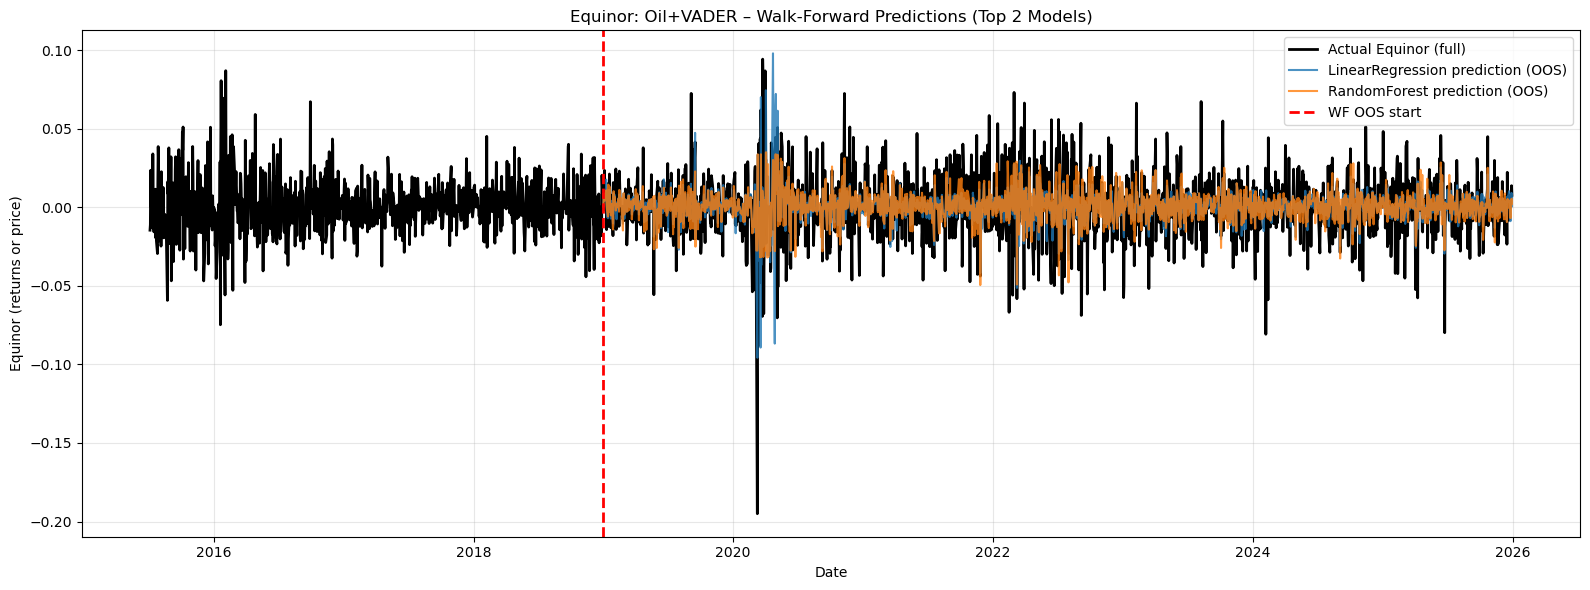

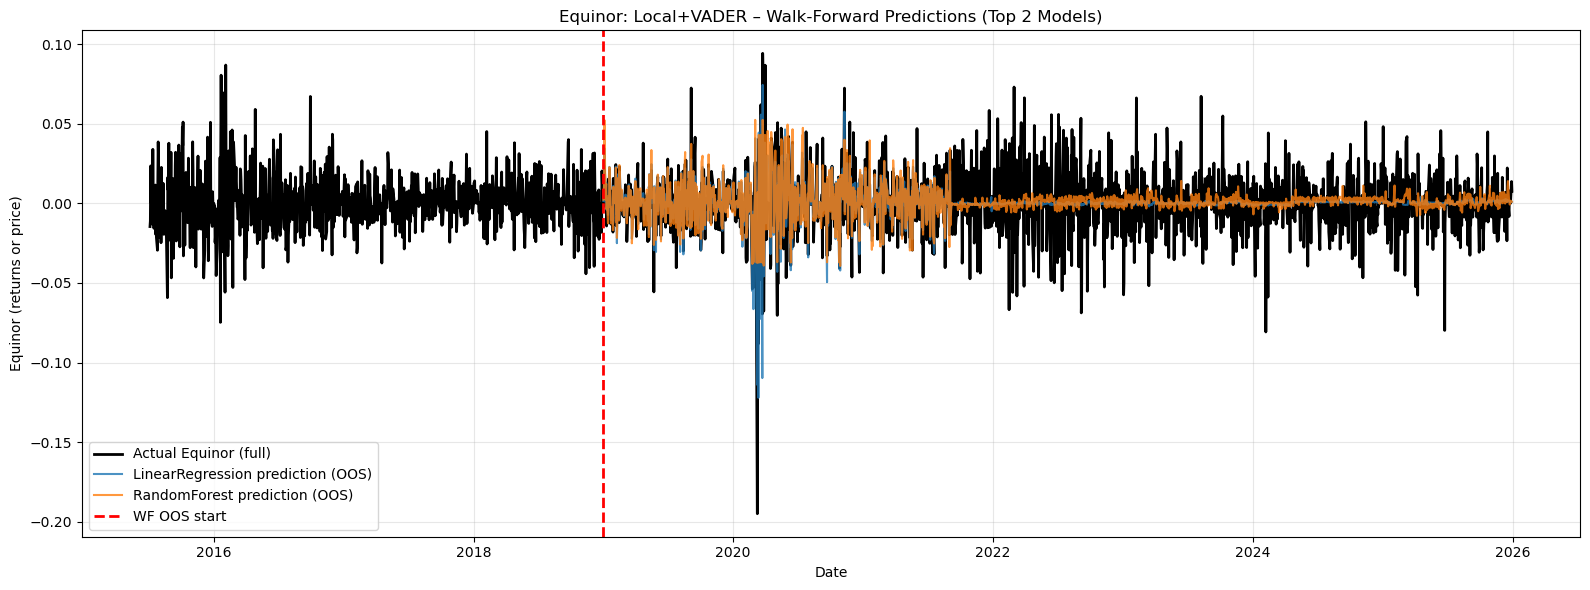

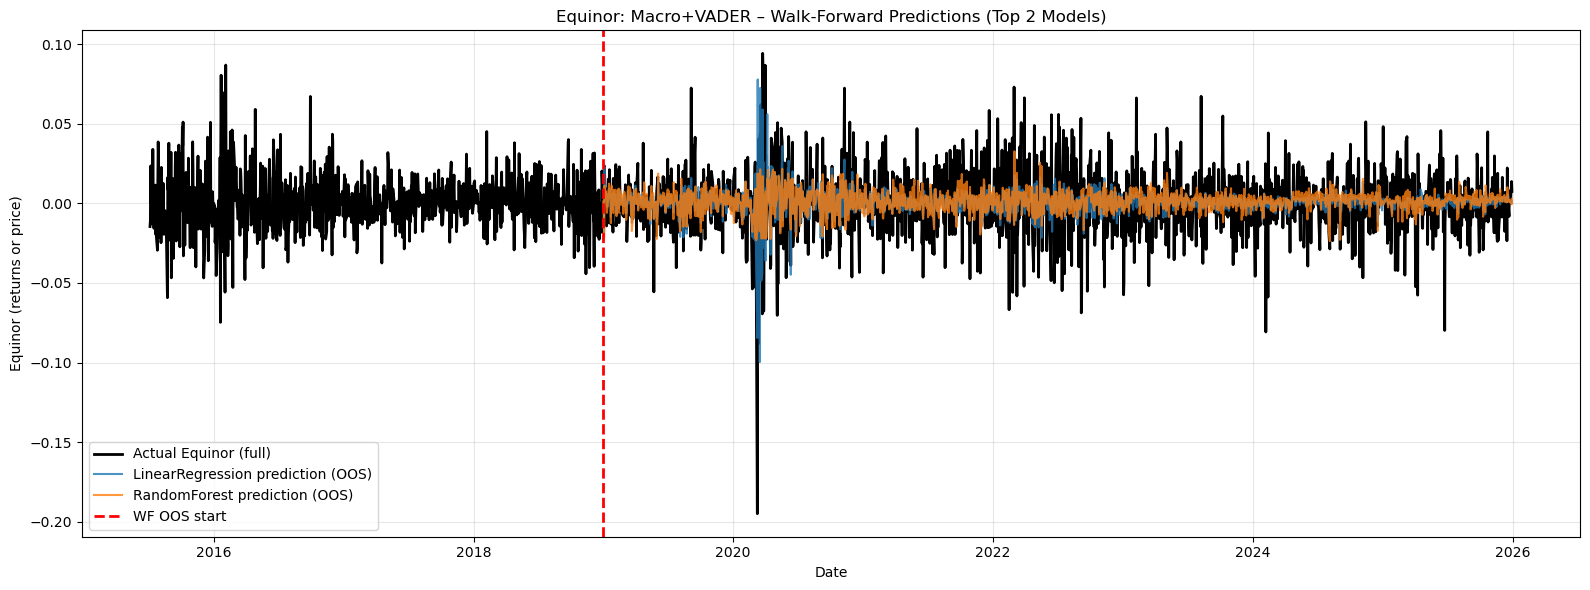

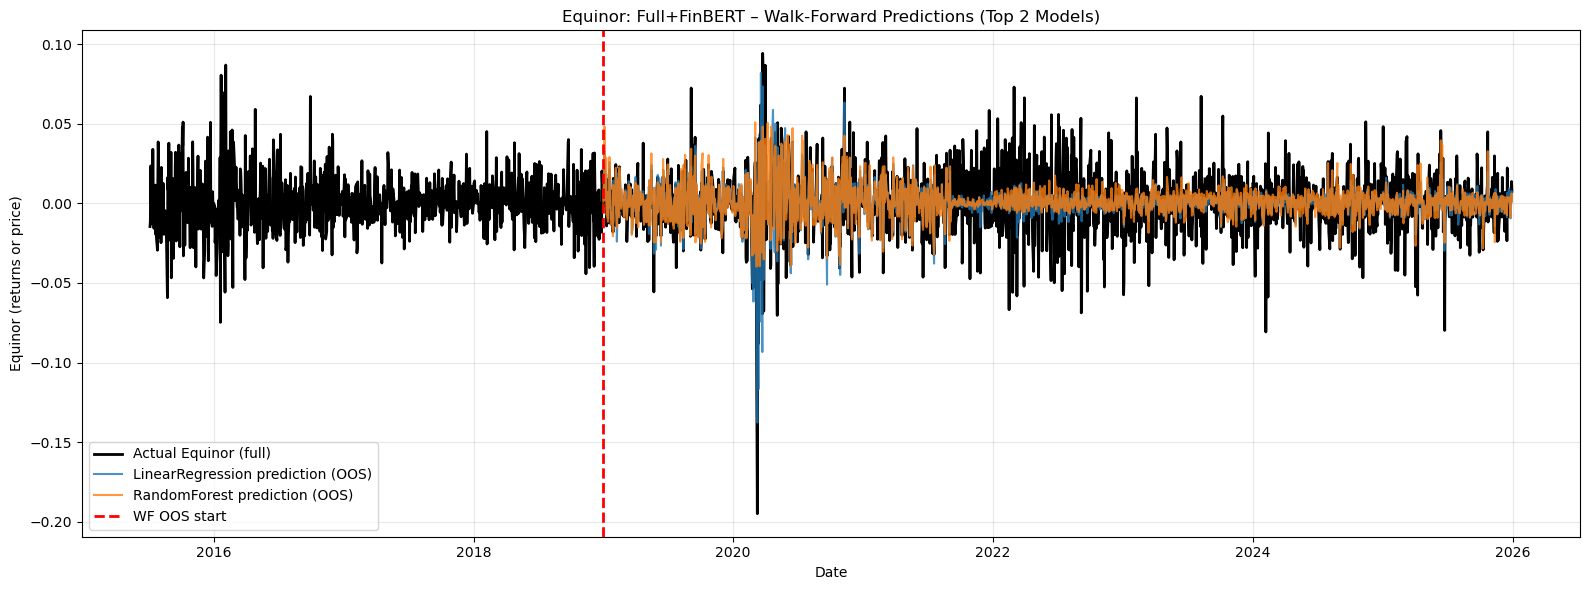

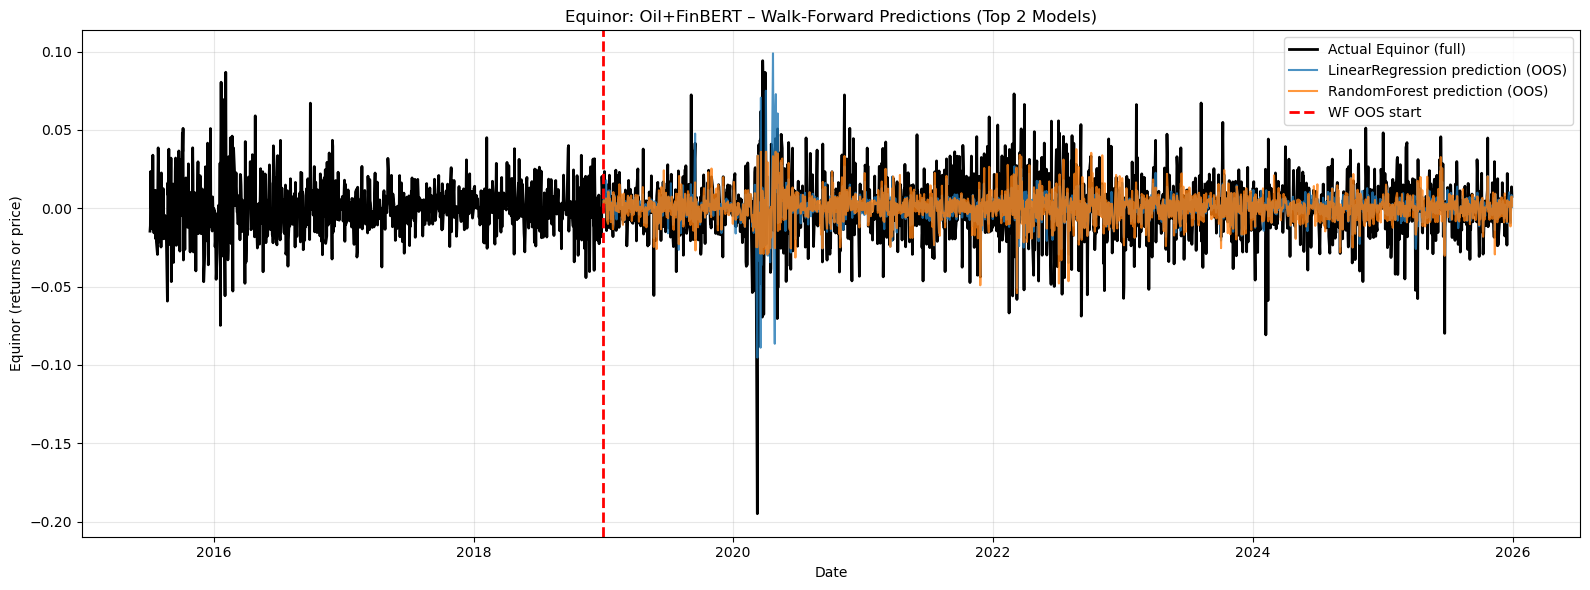

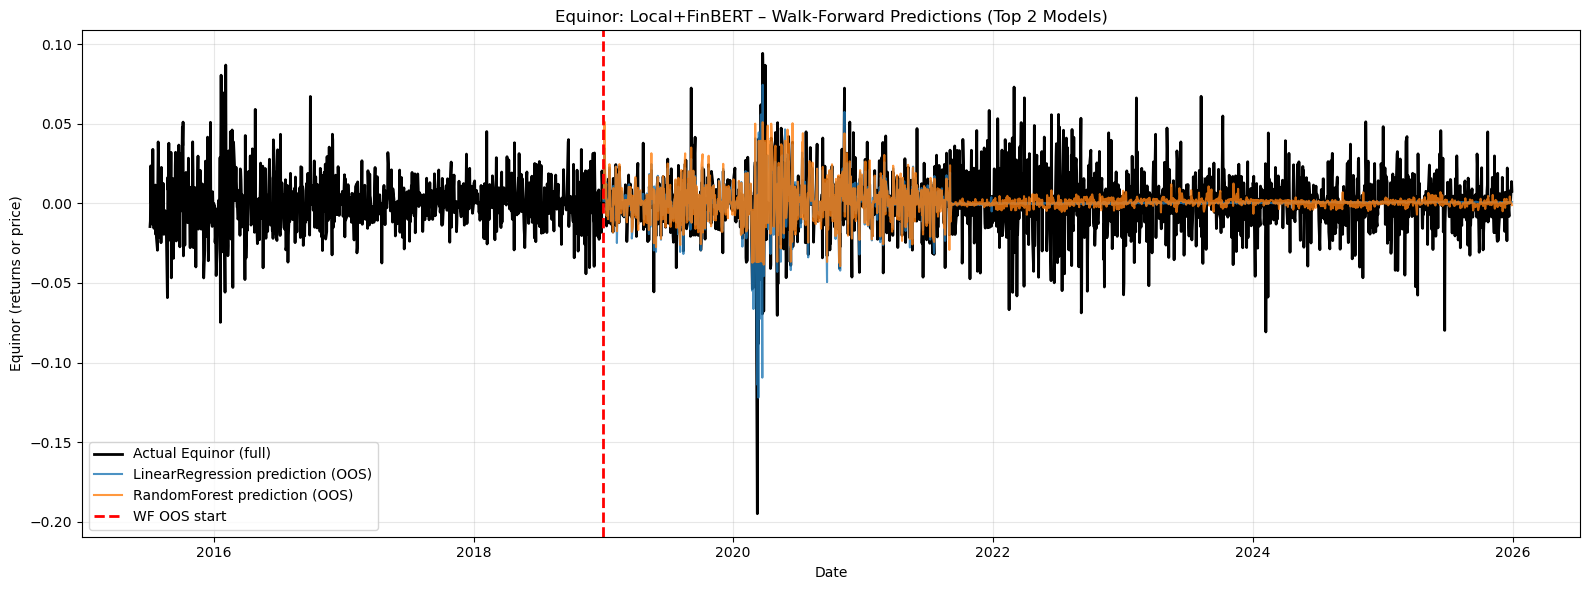

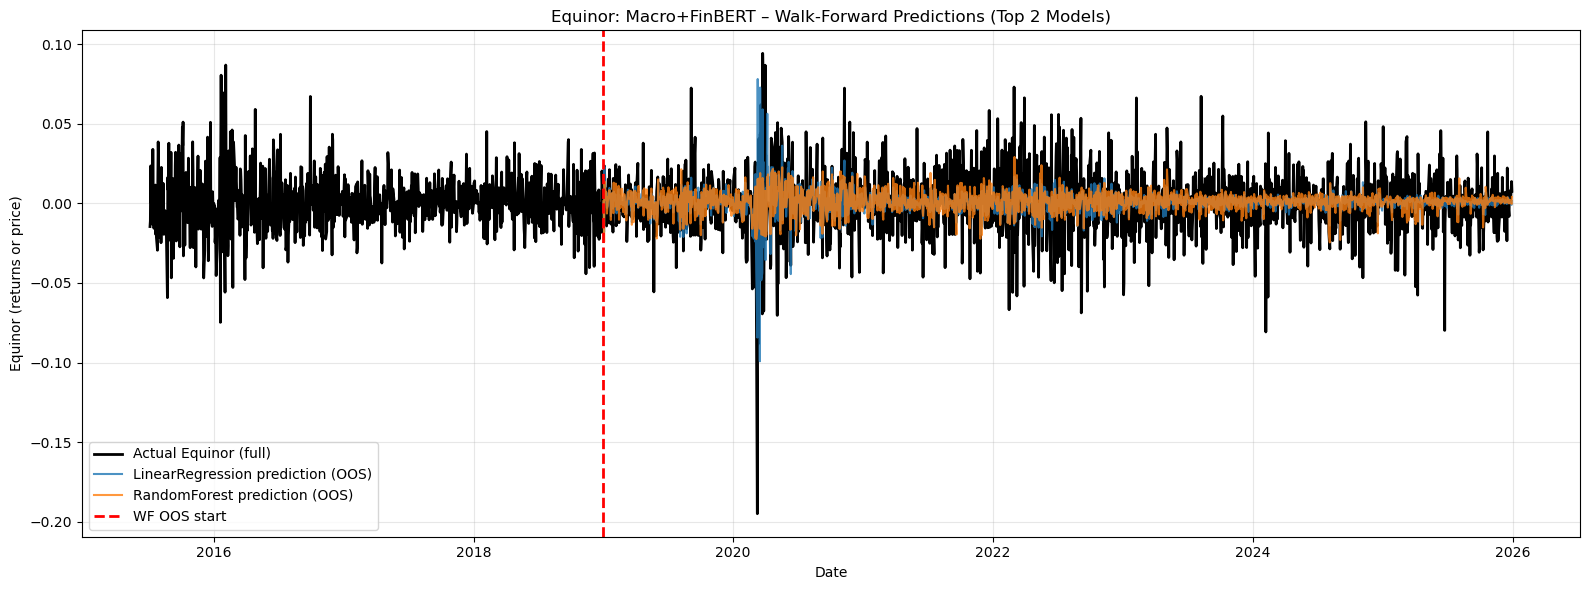

In [77]:
y_full = merged_df["Equinor"]  # full series for plotting

# ===== Full sentiment =====
plot_wf_top_models(results_full_wf,  preds_full_wf,  y_full, title_prefix="Full+FullSentiment",  top_n=2)
plot_wf_top_models(results_oil_wf,   preds_oil_wf,   y_full, title_prefix="Oil+FullSentiment",   top_n=2)
plot_wf_top_models(results_local_wf, preds_local_wf, y_full, title_prefix="Local+FullSentiment", top_n=2)
plot_wf_top_models(results_macro_wf, preds_macro_wf, y_full, title_prefix="Macro+FullSentiment", top_n=2)

# ===== VADER only =====
plot_wf_top_models(results_full_wf_vader,  preds_full_wf_vader,  y_full, title_prefix="Full+VADER",  top_n=2)
plot_wf_top_models(results_oil_wf_vader,   preds_oil_wf_vader,   y_full, title_prefix="Oil+VADER",   top_n=2)
plot_wf_top_models(results_local_wf_vader, preds_local_wf_vader, y_full, title_prefix="Local+VADER", top_n=2)
plot_wf_top_models(results_macro_wf_vader, preds_macro_wf_vader, y_full, title_prefix="Macro+VADER", top_n=2)

# ===== FinBERT only =====
plot_wf_top_models(results_full_wf_finbert,  preds_full_wf_finbert,  y_full, title_prefix="Full+FinBERT",  top_n=2)
plot_wf_top_models(results_oil_wf_finbert,   preds_oil_wf_finbert,   y_full, title_prefix="Oil+FinBERT",   top_n=2)
plot_wf_top_models(results_local_wf_finbert, preds_local_wf_finbert, y_full, title_prefix="Local+FinBERT", top_n=2)
plot_wf_top_models(results_macro_wf_finbert, preds_macro_wf_finbert, y_full, title_prefix="Macro+FinBERT", top_n=2)


In [81]:
all_summaries = []

all_summaries.append(summarize_wf(results_full_wf, "Full+FullSentiment"))
all_summaries.append(summarize_wf(results_macro_wf, "Macro+FullSentiment"))
all_summaries.append(summarize_wf(results_local_wf, "Local+FullSentiment"))
all_summaries.append(summarize_wf(results_oil_wf, "Oil+FullSentiment"))

all_summaries.append(summarize_wf(results_full_wf_finbert, "Full+FinBERT"))
all_summaries.append(summarize_wf(results_macro_wf_finbert, "Macro+FinBERT"))
all_summaries.append(summarize_wf(results_local_wf_finbert, "Local+FinBERT"))
all_summaries.append(summarize_wf(results_oil_wf_finbert, "Oil+FinBERT"))

all_summaries.append(summarize_wf(results_full_wf_vader, "Full+VADER"))
all_summaries.append(summarize_wf(results_macro_wf_vader, "Macro+VADER"))
all_summaries.append(summarize_wf(results_local_wf_vader, "Local+VADER"))
all_summaries.append(summarize_wf(results_oil_wf_vader, "Oil+VADER"))

summary_df_wf = pd.concat(all_summaries, ignore_index=True)
print(summary_df_wf)

               model      RMSE       MAE        R2  Hit_Ratio  \
0           LightGBM  0.016696  0.012255  0.217840   0.653082   
1   LinearRegression  0.015447  0.011452  0.311182   0.680971   
2                MLP  0.017229  0.012250  0.194236   0.657549   
3          NaiveLast  0.027388  0.020404 -1.048720   0.485851   
4          NaiveZero  0.019157  0.013850 -0.002536   0.000000   
..               ...       ...       ...       ...        ...   
79               MLP  0.019987  0.014477 -0.103857   0.602606   
80         NaiveLast  0.027388  0.020404 -1.048720   0.485851   
81         NaiveZero  0.019157  0.013850 -0.002536   0.000000   
82      RandomForest  0.017744  0.013057  0.139465   0.623245   
83           XGBoost  0.018409  0.013555  0.074932   0.599163   

                 Setup  
0   Full+FullSentiment  
1   Full+FullSentiment  
2   Full+FullSentiment  
3   Full+FullSentiment  
4   Full+FullSentiment  
..                 ...  
79           Oil+VADER  
80           Oil+VA

In [85]:
all_single = []

# FullSentiment
all_single.append((results_fulldf_fullsenti,  "Full+FullSentiment"))
all_single.append((results_macrodf_fullsenti, "Macro+FullSentiment"))
all_single.append((results_localdf_fullsenti, "Local+FullSentiment"))
all_single.append((results_oildf_fullsenti,   "Oil+FullSentiment"))

# FinBERT
all_single.append((results_fulldf_finbert,  "Full+FinBERT"))
all_single.append((results_macrodf_finbert, "Macro+FinBERT"))
all_single.append((results_localdf_finbert, "Local+FinBERT"))
all_single.append((results_oildf_finbert,   "Oil+FinBERT"))

# VADER
all_single.append((results_fulldf_vader,  "Full+VADER"))
all_single.append((results_macrodf_vader, "Macro+VADER"))
all_single.append((results_localdf_vader, "Local+VADER"))
all_single.append((results_oildf_vader,   "Oil+VADER"))

tagged = []
for df, setup in all_single:
    tmp = df.copy()
    tmp["Setup"] = setup
    tagged.append(tmp)

summary_df_single = pd.concat(tagged)
print(summary_df_single)

              Model  Test_MAE  Test_RMSE  Test_MSE   Test_R2  Hit_Ratio  \
0      RandomForest  0.011309   0.015441  0.000238  0.122565   0.547206   
1           XGBoost  0.011351   0.015509  0.000241  0.114785   0.558767   
2  LinearRegression  0.011331   0.015565  0.000242  0.108430   0.545279   
3          LightGBM  0.011505   0.015654  0.000245  0.098218   0.554913   
4               MLP  0.012057   0.016046  0.000257  0.052458   0.558767   
0      RandomForest  0.012227   0.016905  0.000286 -0.051674   0.499037   
1  LinearRegression  0.012150   0.017051  0.000291 -0.069925   0.481696   
2           XGBoost  0.012388   0.017286  0.000299 -0.099718   0.475915   
3          LightGBM  0.012869   0.017301  0.000299 -0.101601   0.475915   
4               MLP  0.015225   0.020622  0.000425 -0.565103   0.487476   
0  LinearRegression  0.011828   0.016516  0.000273 -0.003833   0.491329   
1      RandomForest  0.011951   0.016596  0.000275 -0.013655   0.491329   
2           XGBoost  0.01

In [89]:
summary_df_single.to_csv("Model_single_result.csv")